# 05A FORCE raw log feature contract

> Saved outputs are from an earlier local run. Portable path edits have **not** been re-executed. See the repository README for setup and scientific limitations.


In [1]:
# نصب کتابخانه‌ها در صورت نیاز

import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 250)

EPSILON = 1e-12
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
def sha256_file(
    file_path,
    chunk_size=1024 * 1024,
):
    digest = hashlib.sha256()

    with open(
        file_path,
        "rb",
    ) as file:
        while True:
            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()

In [4]:
RUN_MODE = "full"

# Portable project paths (independent of machine-specific Desktop folders).
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift repository root not found. Open Jupyter from inside the repo "
        "or set STRATASHIFT_REPO_ROOT to its absolute path."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT_ROOT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()


STAGE_01_DIR = (
    PROJECT_ROOT
    / "01_clean_splits_support"
)

FOLD_ASSIGNMENT_PATH = (
    STAGE_01_DIR
    / "10_grouped_5fold_well_assignment.csv"
)

STAGE_04C_DIR = (
    PROJECT_ROOT
    / "04C_shared_class_conditional_transport_bank"
    / "full"
)

STAGE_04C_GATE_PATH = (
    STAGE_04C_DIR
    / "07_transport_bank_gate.json"
)

STAGE_04C_CONFIG_PATH = (
    STAGE_04C_DIR
    / "08_run_configuration.json"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "05A_raw_log_feature_contract"
)

OUTPUT_DIR = (
    OUTPUT_ROOT
    / RUN_MODE
)

PLOT_DIR = (
    OUTPUT_DIR
    / "plots"
)

for directory in [
    OUTPUT_ROOT,
    OUTPUT_DIR,
    PLOT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# ---------------------------------------------------------
# قرارداد اصلی مدل Raw
# ---------------------------------------------------------

PRIMARY_RAW_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "DTC",
    "RDEP",
    "CALI",
    "PEF",
    "SP",
]

# ستون‌های خام احتمالی FORCE برای Audit توسعه آینده.
EXTENDED_RAW_ALLOWLIST = [
    "GR",
    "SGR",
    "CGR",
    "NPHI",
    "RHOB",
    "DRHO",
    "DTC",
    "DTS",
    "RDEP",
    "RMED",
    "RSHA",
    "RMIC",
    "RXO",
    "CALI",
    "DCAL",
    "PEF",
    "SP",
    "BS",
    "ROP",
    "ROPA",
    "MUDWEIGHT",
]

IDENTIFIER_COLUMNS = {
    "WELL",
}

DEPTH_COLUMNS = {
    "DEPTH_MD",
}

SPATIAL_COLUMNS = {
    "X_LOC",
    "Y_LOC",
    "Z_LOC",
}

GEOLOGICAL_CONTEXT_COLUMNS = {
    "GROUP",
    "FORMATION",
}

TARGET_COLUMNS = {
    "FORCE_2020_LITHOFACIES_LITHOLOGY",
    "FORCE_2020_LITHOFACIES_CONFIDENCE",
}

FORBIDDEN_PRIMARY_COLUMNS = (
    IDENTIFIER_COLUMNS
    | DEPTH_COLUMNS
    | SPATIAL_COLUMNS
    | GEOLOGICAL_CONTEXT_COLUMNS
    | TARGET_COLUMNS
)

SENTINEL_VALUES = {
    "SP": [-999.0],
}

POSITIVE_ONLY_FEATURES = {
    "RDEP",
    "RMED",
    "RSHA",
    "RMIC",
    "RXO",
}

# فقط برای رتبه‌بندی Candidateهای توسعه آینده؛
# PRIMARY_RAW_FEATURES مستقل از این Thresholdها قفل شده‌اند.
EXTENDED_MIN_OBSERVED_RATE = 0.50
EXTENDED_MIN_SUPPORTING_WELLS = 20

TOP_REDUNDANT_PAIRS_TO_PLOT = 8
MAX_SCATTER_ROWS = 30_000
MAX_WELLS_IN_MISSINGNESS_HEATMAP = 98

required_paths = [
    TRAIN_PATH,
    FOLD_ASSIGNMENT_PATH,
    STAGE_04C_GATE_PATH,
    STAGE_04C_CONFIG_PATH,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Required inputs are missing:\n"
        + "\n".join(missing_paths)
    )

print("Output:", OUTPUT_DIR)
print("Primary raw features:", PRIMARY_RAW_FEATURES)

Output: ${STRATASHIFT_ARTIFACT_ROOT}/05A_raw_log_feature_contract/full
Primary raw features: ['GR', 'NPHI', 'RHOB', 'DTC', 'RDEP', 'CALI', 'PEF', 'SP']


In [5]:
with open(
    STAGE_04C_GATE_PATH,
    "r",
    encoding="utf-8",
) as file:
    stage_04c_gate = json.load(file)

with open(
    STAGE_04C_CONFIG_PATH,
    "r",
    encoding="utf-8",
) as file:
    stage_04c_config = json.load(file)

stage_04c_audit = {
    "stage_04c_passed": bool(
        stage_04c_gate.get(
            "overall_transport_bank_passed",
            False,
        )
    ),
    "stage_04c_full_run": (
        stage_04c_config.get(
            "run_mode"
        )
        == "full"
    ),
    "stage_04c_official_test_unused": (
        stage_04c_config.get(
            "official_test_used"
        )
        is False
    ),
    "same_primary_features_as_transport_bank": (
        set(
            PRIMARY_RAW_FEATURES
        )
        == set(
            stage_04c_config.get(
                "features",
                [],
            )
        )
    ),
}

print(
    json.dumps(
        stage_04c_audit,
        indent=2,
    )
)

if not all(
    stage_04c_audit.values()
):
    raise RuntimeError(
        "Stage 04C audit failed."
    )

{
  "stage_04c_passed": true,
  "stage_04c_full_run": true,
  "stage_04c_official_test_unused": true,
  "same_primary_features_as_transport_bank": true
}


In [6]:
def detect_csv_format(
    file_path,
    num_lines=5,
):
    encodings = [
        "utf-8",
        "latin1",
        "iso-8859-1",
        "cp1252",
    ]

    for encoding in encodings:
        try:
            with open(
                file_path,
                "r",
                encoding=encoding,
            ) as file:
                first_lines = [
                    file.readline()
                    for _ in range(num_lines)
                ]

            if any(
                "," in line
                for line in first_lines
            ):
                delimiter = ","
            elif any(
                ";" in line
                for line in first_lines
            ):
                delimiter = ";"
            elif any(
                "\t" in line
                for line in first_lines
            ):
                delimiter = "\t"
            else:
                delimiter = ","

            return {
                "sep": delimiter,
                "encoding": encoding,
            }

        except UnicodeDecodeError:
            continue

    return {
        "sep": ",",
        "encoding": "utf-8",
    }


csv_format = detect_csv_format(
    TRAIN_PATH
)

train_raw = pd.read_csv(
    TRAIN_PATH,
    sep=csv_format["sep"],
    encoding=csv_format["encoding"],
    low_memory=False,
)

train_raw[
    "ORIGINAL_ROW_ID"
] = np.arange(
    len(train_raw),
    dtype=np.int64,
)

fold_assignment_raw = pd.read_csv(
    FOLD_ASSIGNMENT_PATH
)

well_candidates = [
    column
    for column
    in fold_assignment_raw.columns
    if column.upper() == "WELL"
]

fold_candidates = [
    column
    for column
    in fold_assignment_raw.columns
    if (
        "FOLD" in column.upper()
        and "SCORE" not in column.upper()
    )
]

if not well_candidates or not fold_candidates:
    raise ValueError(
        "Could not infer WELL/FOLD columns."
    )

fold_assignment = (
    fold_assignment_raw[
        [
            well_candidates[0],
            fold_candidates[0],
        ]
    ]
    .rename(
        columns={
            well_candidates[0]: "WELL",
            fold_candidates[0]: "GROUP_FOLD",
        }
    )
    .drop_duplicates(
        subset=["WELL"]
    )
    .copy()
)

fold_assignment[
    "GROUP_FOLD"
] = pd.to_numeric(
    fold_assignment[
        "GROUP_FOLD"
    ],
    errors="raise",
).astype(int)

well_to_fold = dict(
    zip(
        fold_assignment[
            "WELL"
        ],
        fold_assignment[
            "GROUP_FOLD"
        ],
    )
)

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "WELL"
].map(
    well_to_fold
)

missing_fold_wells = sorted(
    train_raw.loc[
        train_raw[
            "GROUP_FOLD"
        ].isna(),
        "WELL",
    ]
    .dropna()
    .unique()
    .tolist()
)

if missing_fold_wells:
    raise RuntimeError(
        "Train wells without grouped-fold assignment: "
        f"{missing_fold_wells[:20]}"
    )

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "GROUP_FOLD"
].astype(int)

print("Train shape:", train_raw.shape)
print("Train wells:", train_raw["WELL"].nunique())
print("Fold values:", sorted(train_raw["GROUP_FOLD"].unique().tolist()))
print("Columns:", len(train_raw.columns))

Train shape: (1170511, 31)
Train wells: 98
Fold values: [1, 2, 3, 4, 5]
Columns: 31


In [7]:
TARGET_COLUMN = (
    "FORCE_2020_LITHOFACIES_LITHOLOGY"
)

LITHOLOGY_CODES = sorted([
    30000,
    65030,
    65000,
    80000,
    74000,
    70000,
    70032,
    88000,
    86000,
    99000,
    90000,
    93000,
])

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

train_raw[
    "LITHOLOGY_CODE"
] = pd.to_numeric(
    train_raw[
        TARGET_COLUMN
    ],
    errors="coerce",
).astype("Int64")

train_raw[
    "LITHOLOGY_NAME"
] = train_raw[
    "LITHOLOGY_CODE"
].map(
    LITHOLOGY_NAMES
)

unknown_codes = sorted(
    set(
        train_raw[
            "LITHOLOGY_CODE"
        ]
        .dropna()
        .astype(int)
        .unique()
        .tolist()
    )
    - set(
        LITHOLOGY_CODES
    )
)

if unknown_codes:
    raise ValueError(
        f"Unknown lithology codes: {unknown_codes}"
    )

if train_raw[
    "LITHOLOGY_CODE"
].isna().any():
    raise ValueError(
        "Missing target labels exist in train data."
    )

print(
    train_raw[
        [
            "LITHOLOGY_CODE",
            "LITHOLOGY_NAME",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "LITHOLOGY_CODE"
    )
)

        LITHOLOGY_CODE   LITHOLOGY_NAME
98               30000        Sandstone
0                65000            Shale
2587             65030  Sandstone/Shale
3907             70000        Limestone
31133            70032            Chalk
18229            74000         Dolomite
13915            80000             Marl
18212            86000        Anhydrite
76302            88000           Halite
75798            90000             Coal
156315           93000         Basement
11205            99000             Tuff


# 5. Column-role inventory

In [8]:
DERIVED_NAME_TOKENS = [
    "interaction",
    "ratio",
    "indicator",
    "gradient",
    "rolling",
    "flatness",
    "slope",
    "delta",
    "product",
    "cross",
]


def infer_column_role(
    column_name,
):
    upper_name = (
        column_name.upper()
    )

    lower_name = (
        column_name.lower()
    )

    if column_name in IDENTIFIER_COLUMNS:
        return "identifier"

    if column_name in DEPTH_COLUMNS:
        return "depth_context"

    if column_name in SPATIAL_COLUMNS:
        return "spatial_context"

    if column_name in GEOLOGICAL_CONTEXT_COLUMNS:
        return "geological_context"

    if column_name in TARGET_COLUMNS:
        return "target_or_label_metadata"

    if column_name in PRIMARY_RAW_FEATURES:
        return "primary_raw_measurement"

    if column_name in EXTENDED_RAW_ALLOWLIST:
        return "extended_raw_candidate"

    if column_name in {
        "GROUP_FOLD",
        "ORIGINAL_ROW_ID",
        "LITHOLOGY_CODE",
        "LITHOLOGY_NAME",
    }:
        return "analysis_metadata"

    if any(
        token in lower_name
        for token in DERIVED_NAME_TOKENS
    ):
        return "likely_engineered_feature"

    if upper_name.startswith(
        "FORCE_2020_"
    ):
        return "target_or_label_metadata"

    return "unclassified"


column_inventory_rows = []

for column in train_raw.columns:
    series = train_raw[
        column
    ]

    numeric_series = pd.to_numeric(
        series,
        errors="coerce",
    )

    column_inventory_rows.append({
        "column": column,
        "in_original_train_csv": (
            column
            not in {
                "ORIGINAL_ROW_ID",
                "GROUP_FOLD",
                "LITHOLOGY_CODE",
                "LITHOLOGY_NAME",
            }
        ),
        "in_primary_contract": (
            column
            in PRIMARY_RAW_FEATURES
        ),
        "in_extended_allowlist": (
            column
            in EXTENDED_RAW_ALLOWLIST
        ),
        "in_forbidden_primary_set": (
            column
            in FORBIDDEN_PRIMARY_COLUMNS
        ),
        "inferred_role": (
            infer_column_role(
                column
            )
        ),
        "dtype": str(
            series.dtype
        ),
        "rows": int(
            len(
                series
            )
        ),
        "non_null_rows": int(
            series.notna().sum()
        ),
        "numeric_parseable_rows": int(
            numeric_series.notna().sum()
        ),
        "unique_values": int(
            series.nunique(
                dropna=True
            )
        ),
    })

column_role_inventory = pd.DataFrame(
    column_inventory_rows
)

display(
    column_role_inventory
    .sort_values(
        [
            "inferred_role",
            "column",
        ]
    )
)

,column,in_original_train_csv,in_primary_contract,in_extended_allowlist,in_forbidden_primary_set,inferred_role,dtype,rows,non_null_rows,numeric_parseable_rows,unique_values
30,GROUP_FOLD,False,False,False,False,analysis_metadata,int64,1170511,1170511,1170511,5
31,LITHOLOGY_CODE,False,False,False,False,analysis_metadata,Int64,1170511,1170511,1170511,12
32,LITHOLOGY_NAME,False,False,False,False,analysis_metadata,object,1170511,1170511,0,12
29,ORIGINAL_ROW_ID,False,False,False,False,analysis_metadata,int64,1170511,1170511,1170511,1170511
1,DEPTH_MD,True,False,False,True,depth_context,float64,1170511,1170511,1170511,1146418
18,BS,True,False,True,False,extended_raw_candidate,float64,1170511,682657,682657,152
21,DCAL,True,False,True,False,extended_raw_candidate,float64,1170511,298833,298833,264010
22,DRHO,True,False,True,False,extended_raw_candidate,float64,1170511,987857,987857,930870
20,DTS,True,False,True,False,extended_raw_candidate,float64,1170511,174613,174613,172930
23,MUDWEIGHT,True,False,True,False,extended_raw_candidate,float64,1170511,316151,316151,276


In [9]:
def clean_raw_feature(
    dataframe,
    feature,
):
    values = pd.to_numeric(
        dataframe[
            feature
        ],
        errors="coerce",
    ).astype(float)

    raw_numeric_mask = values.notna().to_numpy()

    sentinel_mask = np.zeros(
        len(
            values
        ),
        dtype=bool,
    )

    for sentinel in SENTINEL_VALUES.get(
        feature,
        [],
    ):
        sentinel_mask |= np.isclose(
            values.to_numpy(
                dtype=float
            ),
            sentinel,
            rtol=0.0,
            atol=1e-12,
            equal_nan=False,
        )

    values.loc[
        sentinel_mask
    ] = np.nan

    nonfinite_mask = (
        ~np.isfinite(
            values.to_numpy(
                dtype=float
            )
        )
    )

    values.loc[
        nonfinite_mask
    ] = np.nan

    nonpositive_mask = np.zeros(
        len(
            values
        ),
        dtype=bool,
    )

    if feature in POSITIVE_ONLY_FEATURES:
        nonpositive_mask = (
            values.notna().to_numpy()
            & (
                values.to_numpy(
                    dtype=float
                )
                <= 0
            )
        )

        values.loc[
            nonpositive_mask
        ] = np.nan

    return {
        "values": values,
        "raw_numeric_mask": raw_numeric_mask,
        "sentinel_mask": sentinel_mask,
        "nonfinite_mask": nonfinite_mask,
        "nonpositive_mask": nonpositive_mask,
    }


missing_primary_features = [
    feature
    for feature
    in PRIMARY_RAW_FEATURES
    if feature
    not in train_raw.columns
]

if missing_primary_features:
    raise KeyError(
        "Primary raw features missing from train.csv: "
        f"{missing_primary_features}"
    )

clean_primary = pd.DataFrame(
    index=train_raw.index
)

clean_extended = pd.DataFrame(
    index=train_raw.index
)

cleaning_masks = {}

for feature in PRIMARY_RAW_FEATURES:
    cleaned = clean_raw_feature(
        train_raw,
        feature,
    )

    clean_primary[
        feature
    ] = cleaned[
        "values"
    ]

    cleaning_masks[
        feature
    ] = cleaned

present_extended_features = [
    feature
    for feature
    in EXTENDED_RAW_ALLOWLIST
    if feature
    in train_raw.columns
]

for feature in present_extended_features:
    cleaned = clean_raw_feature(
        train_raw,
        feature,
    )

    clean_extended[
        feature
    ] = cleaned[
        "values"
    ]

print("Primary matrix:", clean_primary.shape)
print("Extended candidates present:", present_extended_features)

Primary matrix: (1170511, 8)
Extended candidates present: ['GR', 'SGR', 'NPHI', 'RHOB', 'DRHO', 'DTC', 'DTS', 'RDEP', 'RMED', 'RSHA', 'RMIC', 'RXO', 'CALI', 'DCAL', 'PEF', 'SP', 'BS', 'ROP', 'ROPA', 'MUDWEIGHT']


# 7. Overall raw-feature audit

In [10]:
overall_audit_rows = []

for feature in present_extended_features:
    cleaned = clean_raw_feature(
        train_raw,
        feature,
    )

    values = cleaned[
        "values"
    ]

    observed_mask = values.notna()

    observed_wells = int(
        train_raw.loc[
            observed_mask,
            "WELL",
        ].nunique()
    )

    observed_folds = int(
        train_raw.loc[
            observed_mask,
            "GROUP_FOLD",
        ].nunique()
    )

    finite_values = values.loc[
        observed_mask
    ].to_numpy(
        dtype=float
    )

    if finite_values.size > 0:
        q001 = float(
            np.quantile(
                finite_values,
                0.001,
            )
        )

        q01 = float(
            np.quantile(
                finite_values,
                0.01,
            )
        )

        q25 = float(
            np.quantile(
                finite_values,
                0.25,
            )
        )

        q50 = float(
            np.quantile(
                finite_values,
                0.50,
            )
        )

        q75 = float(
            np.quantile(
                finite_values,
                0.75,
            )
        )

        q99 = float(
            np.quantile(
                finite_values,
                0.99,
            )
        )

        q999 = float(
            np.quantile(
                finite_values,
                0.999,
            )
        )

        iqr = float(
            q75
            - q25
        )

        minimum = float(
            np.min(
                finite_values
            )
        )

        maximum = float(
            np.max(
                finite_values
            )
        )

        unique_values = int(
            np.unique(
                finite_values
            ).size
        )
    else:
        q001 = np.nan
        q01 = np.nan
        q25 = np.nan
        q50 = np.nan
        q75 = np.nan
        q99 = np.nan
        q999 = np.nan
        iqr = np.nan
        minimum = np.nan
        maximum = np.nan
        unique_values = 0

    extended_candidate_eligible = bool(
        observed_mask.mean()
        >= EXTENDED_MIN_OBSERVED_RATE
        and observed_wells
        >= EXTENDED_MIN_SUPPORTING_WELLS
        and observed_folds
        == 5
        and unique_values
        >= 10
        and np.isfinite(
            iqr
        )
        and iqr
        > EPSILON
    )

    overall_audit_rows.append({
        "feature": feature,
        "primary_contract": (
            feature
            in PRIMARY_RAW_FEATURES
        ),
        "rows": int(
            len(
                train_raw
            )
        ),
        "observed_rows": int(
            observed_mask.sum()
        ),
        "observed_rate": float(
            observed_mask.mean()
        ),
        "missing_rate": float(
            1.0
            - observed_mask.mean()
        ),
        "supporting_wells": observed_wells,
        "supporting_folds": observed_folds,
        "sentinel_rows_removed": int(
            cleaned[
                "sentinel_mask"
            ].sum()
        ),
        "nonfinite_rows_removed": int(
            cleaned[
                "nonfinite_mask"
            ].sum()
        ),
        "nonpositive_rows_removed": int(
            cleaned[
                "nonpositive_mask"
            ].sum()
        ),
        "unique_values": unique_values,
        "minimum": minimum,
        "q001": q001,
        "q01": q01,
        "q25": q25,
        "median": q50,
        "q75": q75,
        "q99": q99,
        "q999": q999,
        "maximum": maximum,
        "iqr": iqr,
        "positive_only": (
            feature
            in POSITIVE_ONLY_FEATURES
        ),
        "extended_candidate_eligible": (
            extended_candidate_eligible
        ),
    })

overall_raw_feature_audit = pd.DataFrame(
    overall_audit_rows
)

display(
    overall_raw_feature_audit
    .sort_values(
        [
            "primary_contract",
            "observed_rate",
        ],
        ascending=[
            False,
            False,
        ],
    )
)

,feature,primary_contract,rows,observed_rows,observed_rate,missing_rate,supporting_wells,supporting_folds,sentinel_rows_removed,nonfinite_rows_removed,nonpositive_rows_removed,unique_values,minimum,q001,q01,q25,median,q75,q99,q999,maximum,iqr,positive_only,extended_candidate_eligible
0,GR,True,1170511,1170511,1.000000,0.000000,98,5,0,0,0,1133878,0.109284,4.481549,9.994151,47.627218,68.367630,89.035515,182.492200,283.349554,1076.963867,41.408297,False,True
7,RDEP,True,1170511,1159496,0.990590,0.009410,98,5,0,11015,0,1131288,0.031701,0.231773,0.411284,0.910240,1.439000,2.557220,50.844914,1996.335042,1999.887085,1.646980,True,True
5,DTC,True,1170511,1089648,0.930916,0.069084,98,5,0,80863,0,1027931,7.415132,50.104548,59.726792,87.825840,109.585163,140.774464,174.337106,193.238258,320.478882,52.948624,False,True
12,CALI,True,1170511,1082634,0.924924,0.075076,97,5,0,87877,0,874208,2.344000,5.985319,7.811017,9.429712,12.555752,16.710747,22.564078,24.951905,28.278999,7.281036,False,True
3,RHOB,True,1170511,1009242,0.862223,0.137777,98,5,0,161269,0,874676,0.720971,1.341152,1.577624,2.092203,2.321228,2.488580,2.697000,2.905932,3.457820,0.396377,False,True
15,SP,True,1170511,863845,0.738007,0.261993,68,5,402,306666,0,832033,-608.786804,-250.431209,-203.297820,32.449799,55.406425,83.413727,243.589548,511.235300,526.547302,50.963928,False,True
2,NPHI,True,1170511,765409,0.653910,0.346090,98,5,0,405102,0,736868,-0.035822,0.004022,0.045623,0.241365,0.326800,0.422951,0.643720,0.934716,0.999570,0.181587,False,True
14,PEF,True,1170511,671692,0.573845,0.426155,69,5,0,498819,0,657490,0.099718,0.916540,1.594501,3.414440,4.313530,5.968794,39.199951,163.903358,383.129974,2.554354,False,True
8,RMED,False,1170511,1131511,0.966681,0.033319,97,5,0,38993,7,1104587,0.039904,0.200000,0.441654,0.914092,1.443591,2.680968,32.698653,460.850793,1988.616333,1.766876,True,True
4,DRHO,False,1170511,987857,0.843954,0.156046,95,5,0,182654,0,930870,-7429.338867,-1.241603,-0.097321,-0.009253,0.001752,0.021702,0.203404,2.611341,2.836938,0.030955,False,True


# 8. Fold-level coverage audit

In [11]:
fold_audit_rows = []

for fold in sorted(
    train_raw[
        "GROUP_FOLD"
    ].unique()
):
    fold_mask = (
        train_raw[
            "GROUP_FOLD"
        ]
        == fold
    )

    for feature in present_extended_features:
        values = clean_extended.loc[
            fold_mask,
            feature,
        ]

        observed_mask = values.notna()

        fold_audit_rows.append({
            "group_fold": int(
                fold
            ),
            "feature": feature,
            "rows": int(
                fold_mask.sum()
            ),
            "observed_rows": int(
                observed_mask.sum()
            ),
            "observed_rate": float(
                observed_mask.mean()
            ),
            "missing_rate": float(
                1.0
                - observed_mask.mean()
            ),
            "supporting_wells": int(
                train_raw.loc[
                    fold_mask
                    & clean_extended[
                        feature
                    ].notna(),
                    "WELL",
                ].nunique()
            ),
        })

fold_feature_coverage = pd.DataFrame(
    fold_audit_rows
)

display(
    fold_feature_coverage.head(40)
)

,group_fold,feature,rows,observed_rows,observed_rate,missing_rate,supporting_wells
0,1,GR,232674,232674,1.000000,0.000000,20
1,1,SGR,232674,0,0.000000,1.000000,0
2,1,NPHI,232674,160156,0.688328,0.311672,20
3,1,RHOB,232674,199559,0.857676,0.142324,20
4,1,DRHO,232674,193502,0.831644,0.168356,20
5,1,DTC,232674,216573,0.930800,0.069200,20
6,1,DTS,232674,49211,0.211502,0.788498,9
7,1,RDEP,232674,224693,0.965699,0.034301,20
8,1,RMED,232674,224793,0.966129,0.033871,20
9,1,RSHA,232674,91415,0.392889,0.607111,13


# 9. Lithology-level missingness audit

In [12]:
class_missingness_rows = []

for feature in PRIMARY_RAW_FEATURES:
    values = clean_primary[
        feature
    ]

    temporary = pd.DataFrame({
        "LITHOLOGY_CODE": (
            train_raw[
                "LITHOLOGY_CODE"
            ]
        ),
        "LITHOLOGY_NAME": (
            train_raw[
                "LITHOLOGY_NAME"
            ]
        ),
        "WELL": train_raw[
            "WELL"
        ],
        "observed": (
            values.notna()
        ),
    })

    summary = (
        temporary.groupby(
            [
                "LITHOLOGY_CODE",
                "LITHOLOGY_NAME",
            ],
            as_index=False,
        )
        .agg(
            rows=(
                "WELL",
                "size",
            ),
            wells=(
                "WELL",
                "nunique",
            ),
            observed_rows=(
                "observed",
                "sum",
            ),
        )
    )

    summary[
        "feature"
    ] = feature

    summary[
        "observed_rate"
    ] = (
        summary[
            "observed_rows"
        ]
        / summary[
            "rows"
        ]
    )

    summary[
        "missing_rate"
    ] = (
        1.0
        - summary[
            "observed_rate"
        ]
    )

    class_missingness_rows.append(
        summary
    )

class_feature_missingness = pd.concat(
    class_missingness_rows,
    ignore_index=True,
)

display(
    class_feature_missingness.head(50)
)

,LITHOLOGY_CODE,LITHOLOGY_NAME,rows,wells,observed_rows,feature,observed_rate,missing_rate
0,30000,Sandstone,168937,98,168937,GR,1.000000,0.000000
1,65000,Shale,720803,98,720803,GR,1.000000,0.000000
2,65030,Sandstone/Shale,150455,97,150455,GR,1.000000,0.000000
3,70000,Limestone,56320,94,56320,GR,1.000000,0.000000
4,70032,Chalk,10513,11,10513,GR,1.000000,0.000000
5,74000,Dolomite,1688,37,1688,GR,1.000000,0.000000
6,80000,Marl,33329,73,33329,GR,1.000000,0.000000
7,86000,Anhydrite,1085,6,1085,GR,1.000000,0.000000
8,88000,Halite,8213,3,8213,GR,1.000000,0.000000
9,90000,Coal,3820,51,3820,GR,1.000000,0.000000


# 10. WELL-level coverage and missingness

In [13]:
well_missingness_rows = []

for well, well_indices in train_raw.groupby(
    "WELL"
).groups.items():
    well_indices = list(
        well_indices
    )

    fold_value = int(
        train_raw.loc[
            well_indices,
            "GROUP_FOLD",
        ].iloc[0]
    )

    for feature in PRIMARY_RAW_FEATURES:
        values = clean_primary.loc[
            well_indices,
            feature,
        ]

        well_missingness_rows.append({
            "WELL": well,
            "GROUP_FOLD": fold_value,
            "feature": feature,
            "rows": int(
                len(
                    values
                )
            ),
            "observed_rows": int(
                values.notna().sum()
            ),
            "observed_rate": float(
                values.notna().mean()
            ),
            "missing_rate": float(
                values.isna().mean()
            ),
        })

well_feature_missingness = pd.DataFrame(
    well_missingness_rows
)

well_complete_feature_count = (
    well_feature_missingness.assign(
        feature_has_any_data=(
            well_feature_missingness[
                "observed_rows"
            ]
            > 0
        )
    )
    .groupby(
        [
            "WELL",
            "GROUP_FOLD",
        ],
        as_index=False,
    )
    .agg(
        raw_features_with_any_data=(
            "feature_has_any_data",
            "sum",
        ),
        mean_observed_rate_across_features=(
            "observed_rate",
            "mean",
        ),
        minimum_feature_observed_rate=(
            "observed_rate",
            "min",
        ),
    )
)

display(
    well_complete_feature_count
    .sort_values(
        [
            "raw_features_with_any_data",
            "mean_observed_rate_across_features",
        ]
    )
    .head(30)
)

,WELL,GROUP_FOLD,raw_features_with_any_data,mean_observed_rate_across_features,minimum_feature_observed_rate
89,35/8-4,3,6,0.742202,0.0
64,34/11-1,5,6,0.744173,0.0
52,31/5-4 S,4,7,0.354240,0.0
81,35/11-12,1,7,0.410207,0.0
9,16/11-1 ST3,1,7,0.562090,0.0
96,7/1-1,2,7,0.652030,0.0
58,33/9-1,3,7,0.689027,0.0
31,25/6-3,3,7,0.693023,0.0
57,33/6-3 S,2,7,0.700704,0.0
53,31/6-5,5,7,0.704192,0.0


# 11. Physical-validity and extreme-value audit

In [14]:
physical_validity_rows = []

overall_audit_index = (
    overall_raw_feature_audit
    .set_index(
        "feature"
    )
)

for feature in PRIMARY_RAW_FEATURES:
    values = clean_primary[
        feature
    ]

    observed_values = values.dropna().to_numpy(
        dtype=float
    )

    q01 = float(
        overall_audit_index.loc[
            feature,
            "q01",
        ]
    )

    q99 = float(
        overall_audit_index.loc[
            feature,
            "q99",
        ]
    )

    q001 = float(
        overall_audit_index.loc[
            feature,
            "q001",
        ]
    )

    q999 = float(
        overall_audit_index.loc[
            feature,
            "q999",
        ]
    )

    outside_01_99 = int(
        (
            (
                observed_values
                < q01
            )
            | (
                observed_values
                > q99
            )
        ).sum()
    )

    outside_001_999 = int(
        (
            (
                observed_values
                < q001
            )
            | (
                observed_values
                > q999
            )
        ).sum()
    )

    physical_validity_rows.append({
        "feature": feature,
        "observed_rows": int(
            len(
                observed_values
            )
        ),
        "minimum": float(
            np.min(
                observed_values
            )
        ),
        "maximum": float(
            np.max(
                observed_values
            )
        ),
        "q001": q001,
        "q01": q01,
        "q99": q99,
        "q999": q999,
        "outside_q01_q99_rows": (
            outside_01_99
        ),
        "outside_q01_q99_rate": float(
            outside_01_99
            / len(
                observed_values
            )
        ),
        "outside_q001_q999_rows": (
            outside_001_999
        ),
        "outside_q001_q999_rate": float(
            outside_001_999
            / len(
                observed_values
            )
        ),
        "hard_cleaning_applied": (
            "sentinel/nonfinite/nonpositive-only"
        ),
        "outlier_clipping_applied": False,
    })

physical_validity_audit = pd.DataFrame(
    physical_validity_rows
)

display(
    physical_validity_audit
)

,feature,observed_rows,minimum,maximum,q001,q01,q99,q999,outside_q01_q99_rows,outside_q01_q99_rate,outside_q001_q999_rows,outside_q001_q999_rate,hard_cleaning_applied,outlier_clipping_applied
0,GR,1170511,0.109284,1076.963867,4.481549,9.994151,182.492200,283.349554,23412,0.020002,2342,0.002001,sentinel/nonfinite/nonpositive-only,False
1,NPHI,765409,-0.035822,0.999570,0.004022,0.045623,0.643720,0.934716,15310,0.020002,1532,0.002002,sentinel/nonfinite/nonpositive-only,False
2,RHOB,1009242,0.720971,3.457820,1.341152,1.577624,2.697000,2.905932,20184,0.019999,2020,0.002002,sentinel/nonfinite/nonpositive-only,False
3,DTC,1089648,7.415132,320.478882,50.104548,59.726792,174.337106,193.238258,21794,0.020001,2180,0.002001,sentinel/nonfinite/nonpositive-only,False
4,RDEP,1159496,0.031701,1999.887085,0.231773,0.411284,50.844914,1996.335042,23190,0.020000,2320,0.002001,sentinel/nonfinite/nonpositive-only,False
5,CALI,1082634,2.344000,28.278999,5.985319,7.811017,22.564078,24.951905,21654,0.020001,2166,0.002001,sentinel/nonfinite/nonpositive-only,False
6,PEF,671692,0.099718,383.129974,0.916540,1.594501,39.199951,163.903358,13434,0.020000,1344,0.002001,sentinel/nonfinite/nonpositive-only,False
7,SP,863845,-608.786804,526.547302,-250.431209,-203.297820,243.589548,511.235300,17278,0.020001,1728,0.002000,sentinel/nonfinite/nonpositive-only,False


In [15]:
spearman_correlation = (
    clean_primary.corr(
        method="spearman",
        min_periods=500,
    )
)

pearson_correlation = (
    clean_primary.corr(
        method="pearson",
        min_periods=500,
    )
)

pairwise_redundancy_rows = []

for feature_a, feature_b in combinations(
    PRIMARY_RAW_FEATURES,
    2,
):
    pair_values = clean_primary[
        [
            feature_a,
            feature_b,
        ]
    ].dropna()

    spearman_value = float(
        spearman_correlation.loc[
            feature_a,
            feature_b,
        ]
    )

    pearson_value = float(
        pearson_correlation.loc[
            feature_a,
            feature_b,
        ]
    )

    pairwise_redundancy_rows.append({
        "feature_a": feature_a,
        "feature_b": feature_b,
        "pairwise_complete_rows": int(
            len(
                pair_values
            )
        ),
        "spearman_correlation": (
            spearman_value
        ),
        "absolute_spearman_correlation": (
            abs(
                spearman_value
            )
        ),
        "pearson_correlation": (
            pearson_value
        ),
        "absolute_pearson_correlation": (
            abs(
                pearson_value
            )
        ),
    })

pairwise_redundancy = (
    pd.DataFrame(
        pairwise_redundancy_rows
    )
    .sort_values(
        "absolute_spearman_correlation",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

display(
    pairwise_redundancy
)

,feature_a,feature_b,pairwise_complete_rows,spearman_correlation,absolute_spearman_correlation,pearson_correlation,absolute_pearson_correlation
0,RHOB,DTC,967062,-0.838532,0.838532,-0.825593,0.825593
1,NPHI,DTC,735502,0.826679,0.826679,0.788425,0.788425
2,RHOB,RDEP,1005149,0.656644,0.656644,-0.039025,0.039025
3,DTC,RDEP,1082036,-0.647194,0.647194,-0.105184,0.105184
4,NPHI,RHOB,750893,-0.630571,0.630571,-0.623808,0.623808
5,DTC,CALI,1031107,0.594796,0.594796,0.588739,0.588739
6,NPHI,RDEP,761704,-0.559890,0.559890,-0.181104,0.181104
7,RHOB,CALI,964648,-0.527970,0.527970,-0.570643,0.570643
8,NPHI,CALI,732451,0.483498,0.483498,0.446972,0.446972
9,RDEP,CALI,1074485,-0.415307,0.415307,-0.030207,0.030207


In [16]:
extended_eligible_features = (
    overall_raw_feature_audit.loc[
        overall_raw_feature_audit[
            "extended_candidate_eligible"
        ]
        == True,
        "feature",
    ]
    .tolist()
)

PRIMARY_CONTRACT = {
    "contract_name": (
        "FORCE_raw_log_RF_primary_diagnostic_contract"
    ),
    "contract_version": (
        "1.0.0"
    ),
    "purpose": (
        "isolate raw-log model sensitivity from legacy engineered-feature amplification"
    ),
    "input_features": (
        PRIMARY_RAW_FEATURES
    ),
    "input_feature_count": (
        len(
            PRIMARY_RAW_FEATURES
        )
    ),
    "forbidden_model_inputs": sorted(
        FORBIDDEN_PRIMARY_COLUMNS
    ),
    "grouping_column": (
        "WELL"
    ),
    "grouped_fold_column": (
        "GROUP_FOLD"
    ),
    "target_column": (
        TARGET_COLUMN
    ),
    "target_codes": (
        LITHOLOGY_CODES
    ),
    "target_names": (
        LITHOLOGY_NAMES
    ),
    "cleaning_policy": {
        "numeric_coercion": (
            "non-numeric values become missing"
        ),
        "nonfinite_values": (
            "become missing"
        ),
        "sentinel_values": (
            SENTINEL_VALUES
        ),
        "positive_only_features": sorted(
            POSITIVE_ONLY_FEATURES
            & set(
                PRIMARY_RAW_FEATURES
            )
        ),
        "nonpositive_positive_only_values": (
            "become missing"
        ),
        "outlier_clipping": False,
        "row_deletion_for_missing_features": False,
    },
    "outer_fold_preprocessing": {
        "imputer": (
            "one median per feature fitted on outer-training rows only"
        ),
        "imputer_scope": (
            "outer fold specific"
        ),
        "missingness_indicators": False,
        "scaling": False,
        "feature_selection": False,
        "feature_engineering": False,
    },
    "model_family_next_stage": (
        "RandomForestClassifier"
    ),
    "official_test_policy": (
        "locked and unused"
    ),
    "intervention_bank": (
        "04C shared class-conditional transport bank"
    ),
    "interpretation": (
        "direct sensitivity of a raw-log Random Forest representation"
    ),
}

EXTENDED_CANDIDATE_CONTRACT = {
    "contract_name": (
        "FORCE_extended_raw_log_candidate_inventory"
    ),
    "contract_version": (
        "1.0.0"
    ),
    "present_allowlisted_features": (
        present_extended_features
    ),
    "eligibility_policy": {
        "minimum_observed_rate": (
            EXTENDED_MIN_OBSERVED_RATE
        ),
        "minimum_supporting_wells": (
            EXTENDED_MIN_SUPPORTING_WELLS
        ),
        "all_five_folds_required": True,
        "minimum_unique_values": 10,
        "nonzero_iqr_required": True,
    },
    "eligible_features": (
        extended_eligible_features
    ),
    "use_in_primary_raw_RF": False,
    "future_use": (
        "secondary sensitivity analysis or later robust-model candidate search"
    ),
}

PREPROCESSING_POLICY = {
    "policy_name": (
        "FORCE_raw_RF_fold_safe_preprocessing"
    ),
    "version": (
        "1.0.0"
    ),
    "fit_scope": (
        "outer-training rows only"
    ),
    "transform_scope": (
        "outer-validation rows using frozen outer-training statistics"
    ),
    "steps": [
        "numeric coercion",
        "explicit sentinel to missing",
        "nonfinite to missing",
        "nonpositive resistivity to missing",
        "feature-wise median imputation",
    ],
    "excluded_steps": [
        "global preprocessing before grouped split",
        "scaling",
        "feature engineering",
        "missingness indicators",
        "target-dependent imputation",
        "test-informed preprocessing",
    ],
}

print(
    json.dumps(
        PRIMARY_CONTRACT,
        indent=2,
    )
)

{
  "contract_name": "FORCE_raw_log_RF_primary_diagnostic_contract",
  "contract_version": "1.0.0",
  "purpose": "isolate raw-log model sensitivity from legacy engineered-feature amplification",
  "input_features": [
    "GR",
    "NPHI",
    "RHOB",
    "DTC",
    "RDEP",
    "CALI",
    "PEF",
    "SP"
  ],
  "input_feature_count": 8,
  "forbidden_model_inputs": [
    "DEPTH_MD",
    "FORCE_2020_LITHOFACIES_CONFIDENCE",
    "FORCE_2020_LITHOFACIES_LITHOLOGY",
    "FORMATION",
    "GROUP",
    "WELL",
    "X_LOC",
    "Y_LOC",
    "Z_LOC"
  ],
  "grouping_column": "WELL",
  "grouped_fold_column": "GROUP_FOLD",
  "target_column": "FORCE_2020_LITHOFACIES_LITHOLOGY",
  "target_codes": [
    30000,
    65000,
    65030,
    70000,
    70032,
    74000,
    80000,
    86000,
    88000,
    90000,
    93000,
    99000
  ],
  "target_names": {
    "30000": "Sandstone",
    "65000": "Shale",
    "65030": "Sandstone/Shale",
    "70000": "Limestone",
    "70032": "Chalk",
    "74000": "Dolomite

In [17]:
def save_current_figure(
    filename,
):
    plt.tight_layout()
    plt.savefig(
        PLOT_DIR
        / filename,
        dpi=220,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


def draw_labeled_heatmap(
    dataframe,
    title,
    xlabel,
    ylabel,
    filename,
    annotate=False,
    number_format=".2f",
):
    matrix = dataframe.to_numpy(
        dtype=float
    )

    plt.figure(
        figsize=(
            max(
                9,
                0.9
                * dataframe.shape[1],
            ),
            max(
                6,
                0.45
                * dataframe.shape[0],
            ),
        )
    )

    image = plt.imshow(
        matrix,
        aspect="auto",
    )

    plt.colorbar(
        image
    )

    plt.xticks(
        np.arange(
            dataframe.shape[1]
        ),
        dataframe.columns,
        rotation=45,
        ha="right",
    )

    plt.yticks(
        np.arange(
            dataframe.shape[0]
        ),
        dataframe.index,
    )

    plt.xlabel(
        xlabel
    )

    plt.ylabel(
        ylabel
    )

    plt.title(
        title
    )

    if annotate:
        for row_index in range(
            dataframe.shape[0]
        ):
            for column_index in range(
                dataframe.shape[1]
            ):
                value = matrix[
                    row_index,
                    column_index,
                ]

                if np.isfinite(
                    value
                ):
                    plt.text(
                        column_index,
                        row_index,
                        format(
                            value,
                            number_format,
                        ),
                        ha="center",
                        va="center",
                    )

    save_current_figure(
        filename
    )

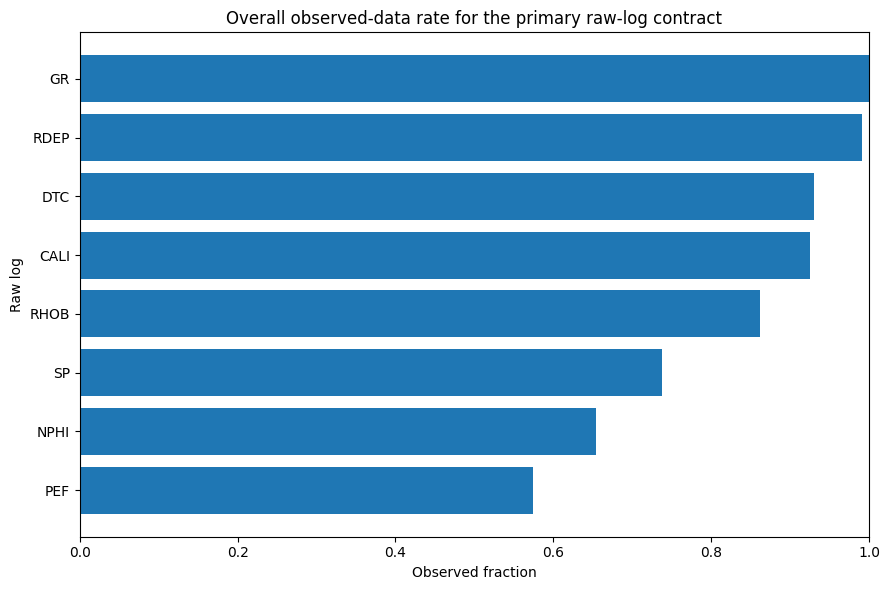

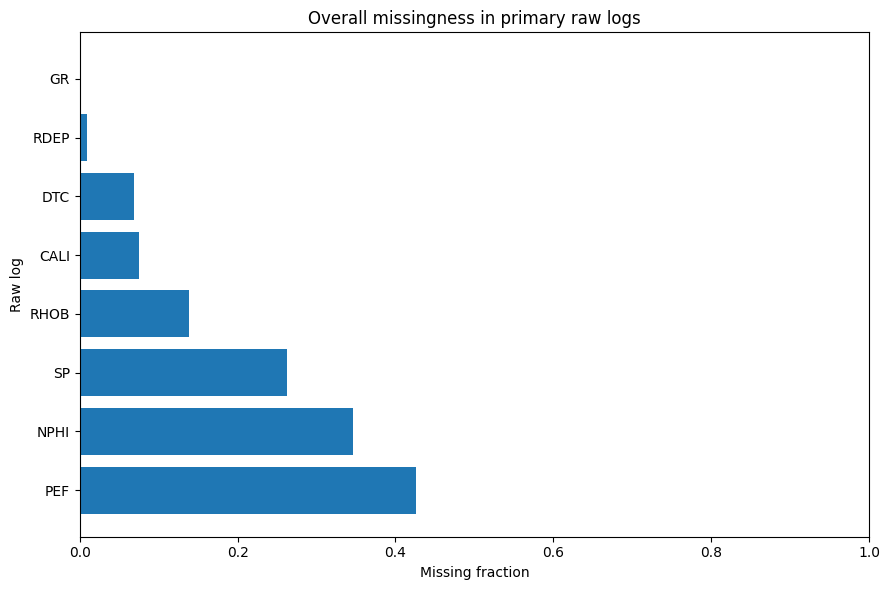

In [18]:
# Plot 01 — Overall observed rate
plot_df = (
    overall_raw_feature_audit.loc[
        overall_raw_feature_audit[
            "feature"
        ].isin(
            PRIMARY_RAW_FEATURES
        )
    ]
    .sort_values(
        "observed_rate",
        ascending=True,
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    plot_df[
        "feature"
    ],
    plot_df[
        "observed_rate"
    ],
)

plt.xlabel(
    "Observed fraction"
)

plt.ylabel(
    "Raw log"
)

plt.xlim(
    0,
    1,
)

plt.title(
    "Overall observed-data rate for the primary raw-log contract"
)

save_current_figure(
    "01_primary_feature_observed_rate.png"
)


# Plot 02 — Missing rate
plt.figure(
    figsize=(9, 6)
)

plt.barh(
    plot_df[
        "feature"
    ],
    plot_df[
        "missing_rate"
    ],
)

plt.xlabel(
    "Missing fraction"
)

plt.ylabel(
    "Raw log"
)

plt.xlim(
    0,
    1,
)

plt.title(
    "Overall missingness in primary raw logs"
)

save_current_figure(
    "02_primary_feature_missing_rate.png"
)

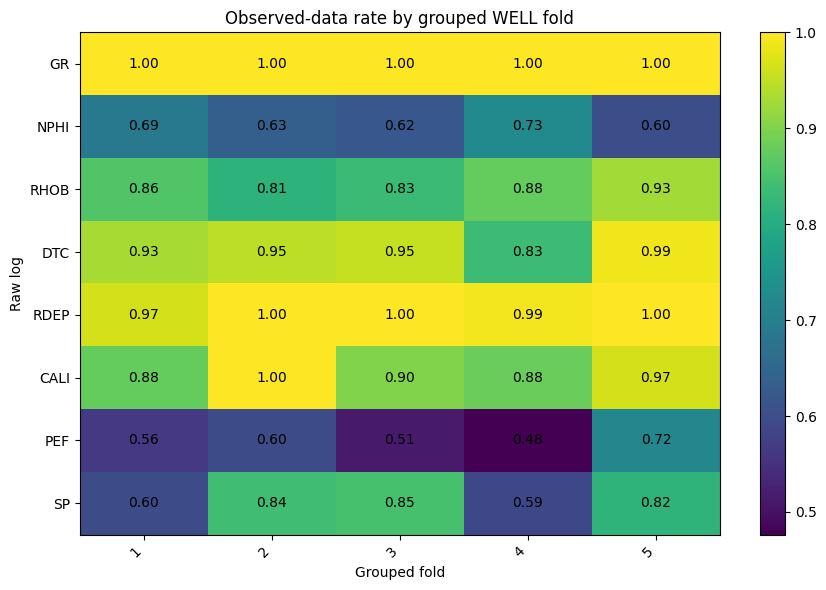

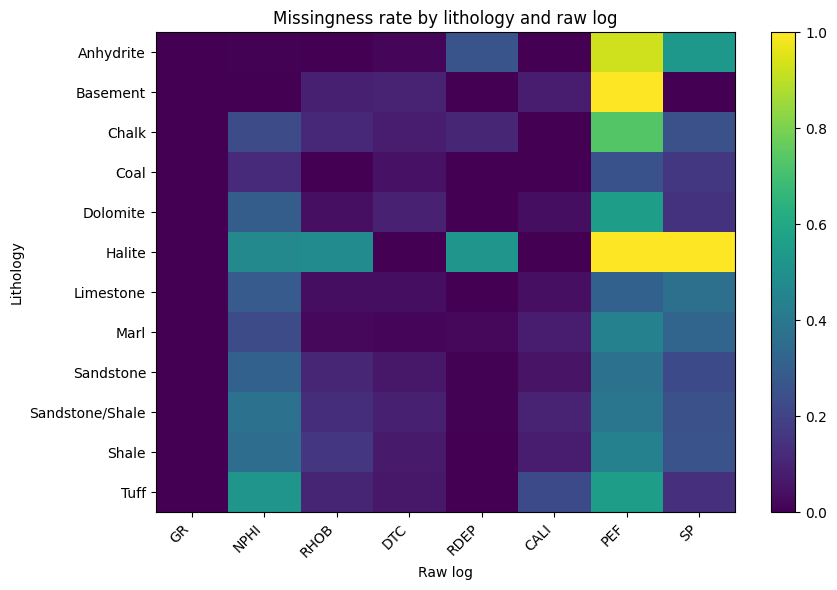

In [19]:
# Plot 03 — Fold-level observed-rate heatmap
fold_matrix = (
    fold_feature_coverage.loc[
        fold_feature_coverage[
            "feature"
        ].isin(
            PRIMARY_RAW_FEATURES
        )
    ]
    .pivot(
        index="feature",
        columns="group_fold",
        values="observed_rate",
    )
    .reindex(
        index=PRIMARY_RAW_FEATURES
    )
)

draw_labeled_heatmap(
    fold_matrix,
    title=(
        "Observed-data rate by grouped WELL fold"
    ),
    xlabel="Grouped fold",
    ylabel="Raw log",
    filename=(
        "03_fold_feature_observed_rate_heatmap.png"
    ),
    annotate=True,
    number_format=".2f",
)


# Plot 04 — Class missingness heatmap
class_matrix = (
    class_feature_missingness.pivot(
        index="LITHOLOGY_NAME",
        columns="feature",
        values="missing_rate",
    )
    .reindex(
        columns=PRIMARY_RAW_FEATURES
    )
)

draw_labeled_heatmap(
    class_matrix,
    title=(
        "Missingness rate by lithology and raw log"
    ),
    xlabel="Raw log",
    ylabel="Lithology",
    filename=(
        "04_class_feature_missingness_heatmap.png"
    ),
    annotate=False,
)

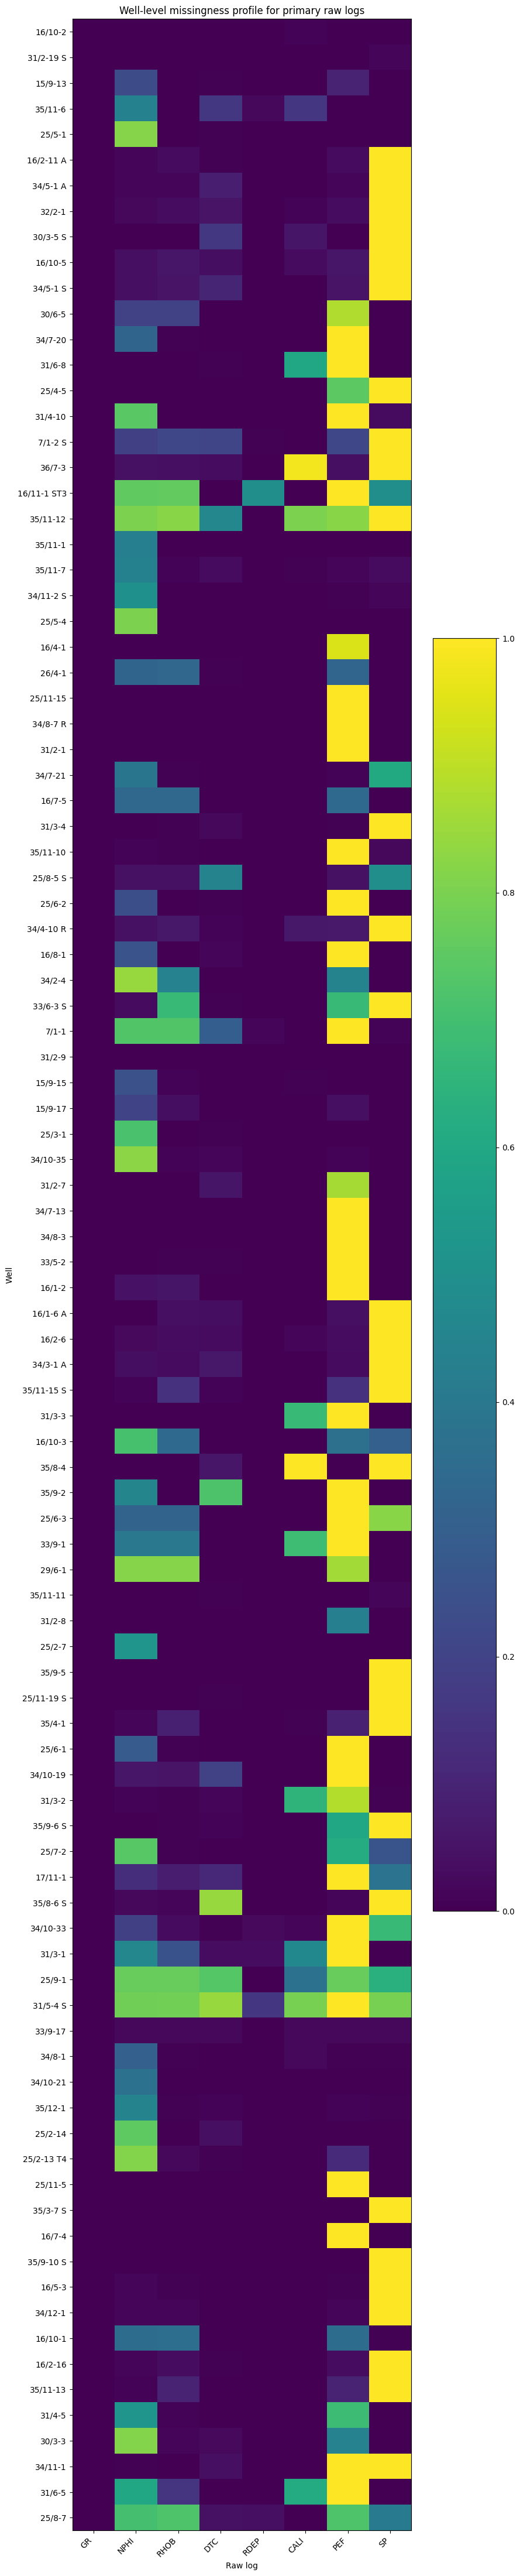

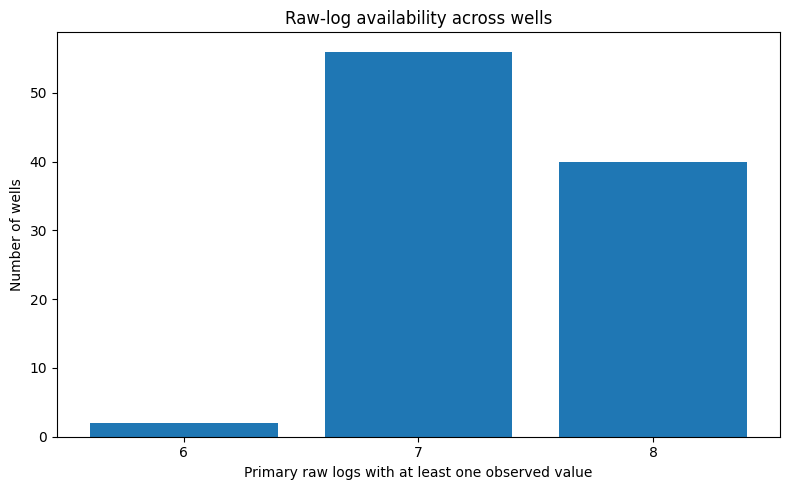

In [20]:
# Plot 05 — WELL missingness heatmap
well_order = (
    well_complete_feature_count.sort_values(
        [
            "GROUP_FOLD",
            "mean_observed_rate_across_features",
        ],
        ascending=[
            True,
            False,
        ],
    )[
        "WELL"
    ]
    .tolist()
)

well_matrix = (
    well_feature_missingness.pivot(
        index="WELL",
        columns="feature",
        values="missing_rate",
    )
    .reindex(
        index=well_order[
            :MAX_WELLS_IN_MISSINGNESS_HEATMAP
        ],
        columns=PRIMARY_RAW_FEATURES,
    )
)

draw_labeled_heatmap(
    well_matrix,
    title=(
        "Well-level missingness profile for primary raw logs"
    ),
    xlabel="Raw log",
    ylabel="Well",
    filename=(
        "05_well_feature_missingness_heatmap.png"
    ),
    annotate=False,
)


# Plot 06 — Number of available features in each well
well_feature_count_distribution = (
    well_complete_feature_count[
        "raw_features_with_any_data"
    ]
    .value_counts()
    .sort_index()
)

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    well_feature_count_distribution.index.astype(
        str
    ),
    well_feature_count_distribution.values,
)

plt.xlabel(
    "Primary raw logs with at least one observed value"
)

plt.ylabel(
    "Number of wells"
)

plt.title(
    "Raw-log availability across wells"
)

save_current_figure(
    "06_well_available_feature_count.png"
)

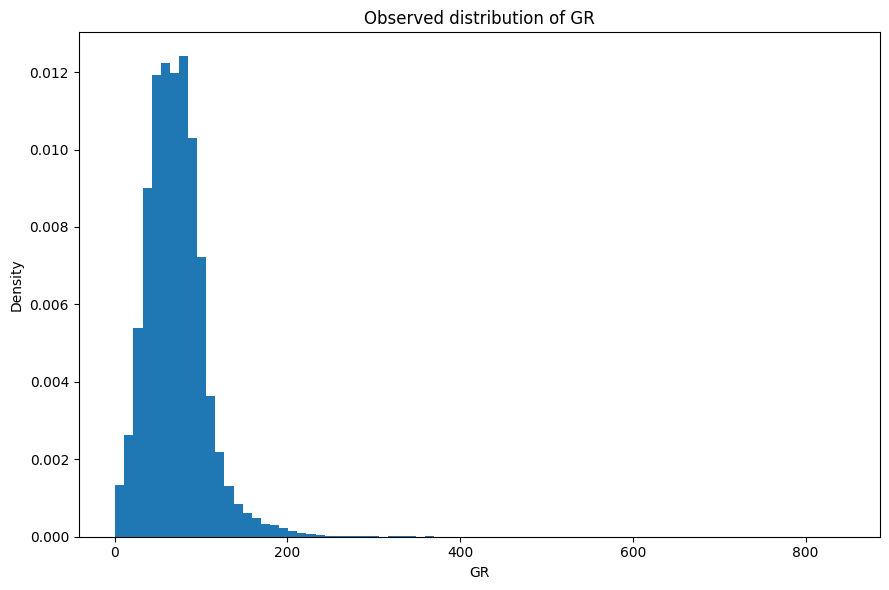

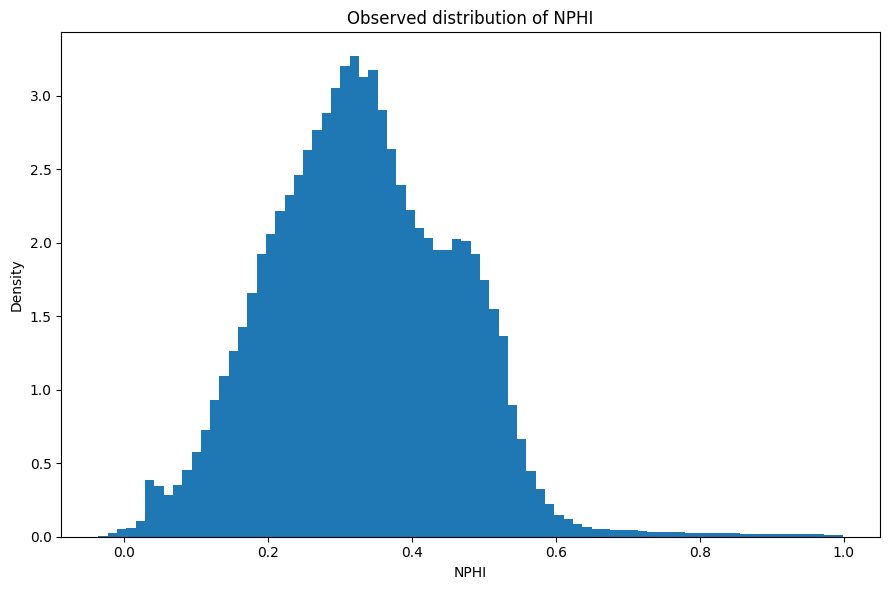

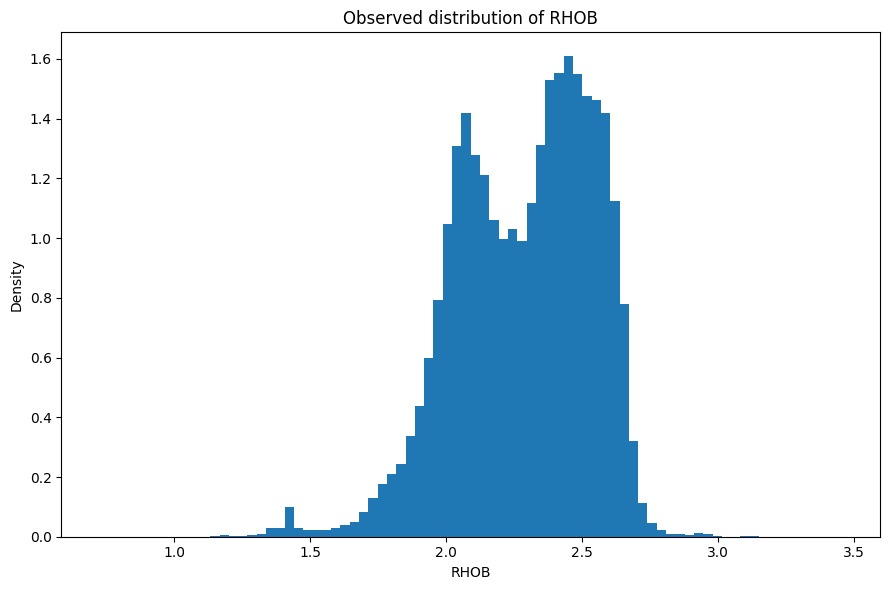

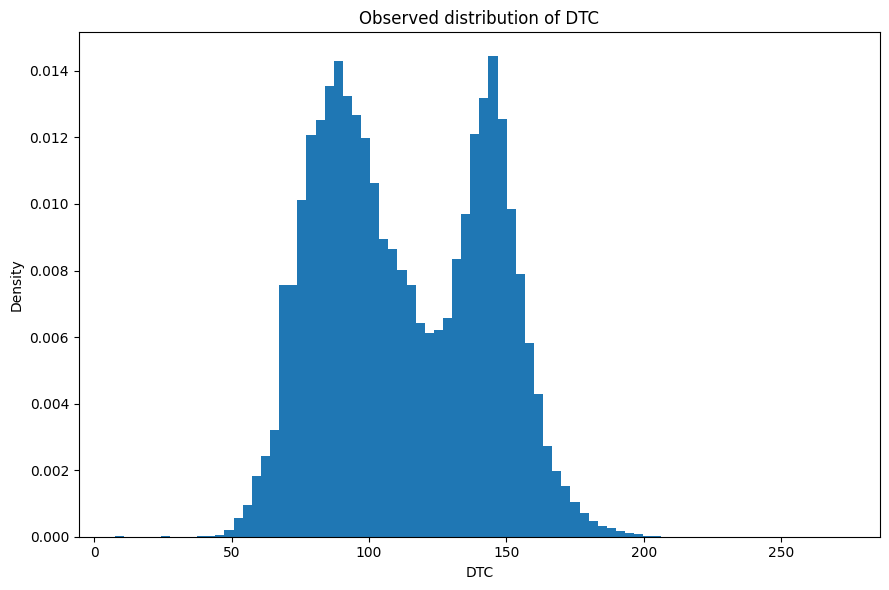

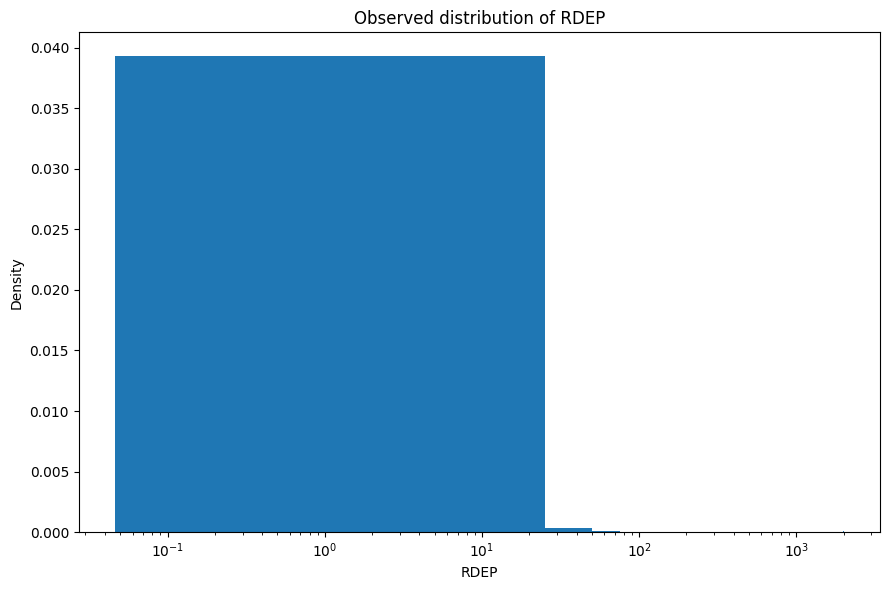

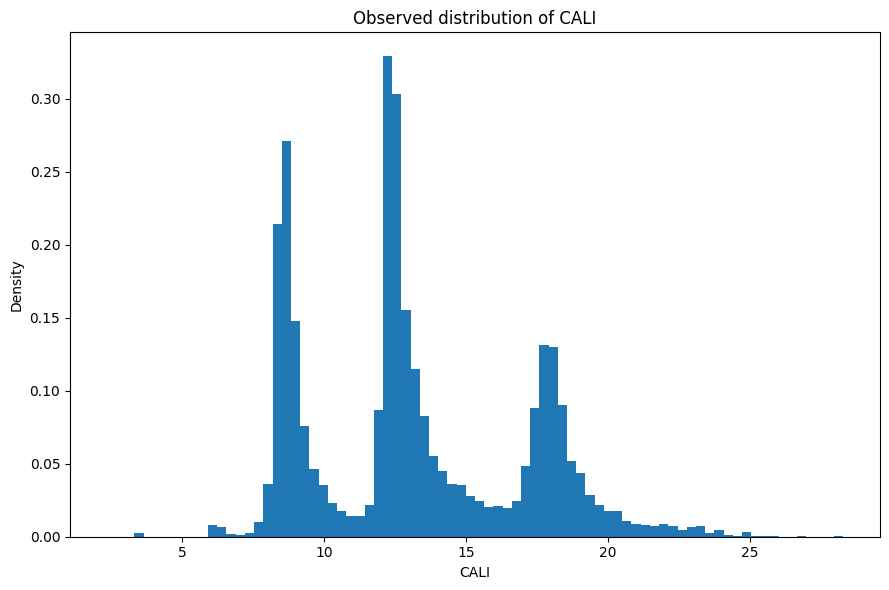

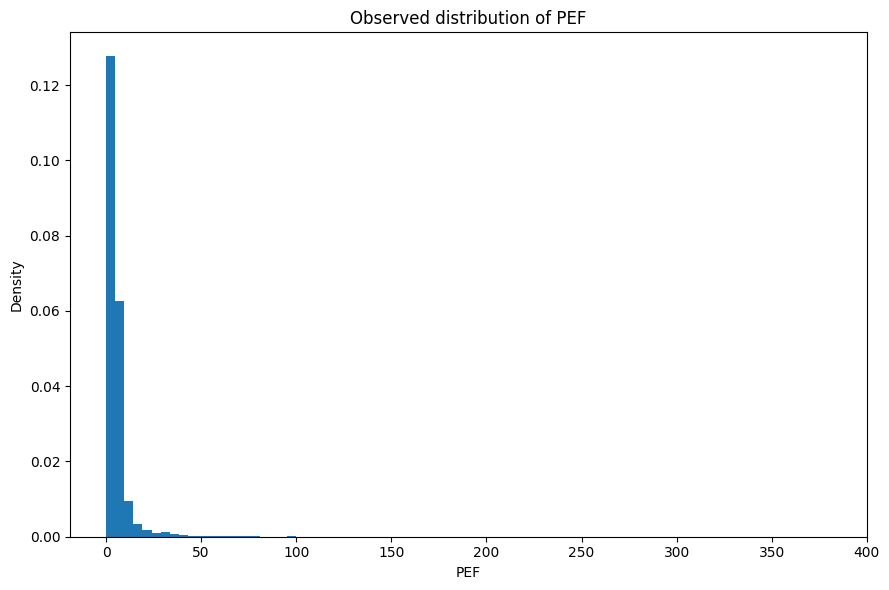

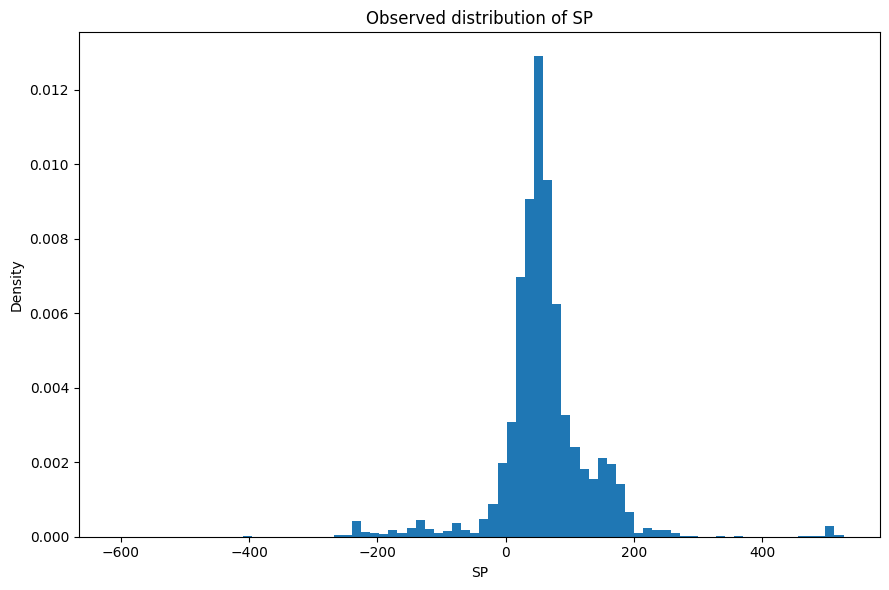

In [21]:
# Plot 07+ — Distribution plots, one figure per feature
for feature in PRIMARY_RAW_FEATURES:
    values = clean_primary[
        feature
    ].dropna()

    plot_values = values

    if len(
        plot_values
    ) > 200_000:
        plot_values = plot_values.sample(
            n=200_000,
            random_state=RANDOM_STATE,
        )

    plt.figure(
        figsize=(9, 6)
    )

    plt.hist(
        plot_values,
        bins=80,
        density=True,
    )

    if feature == "RDEP":
        plt.xscale(
            "log"
        )

    plt.xlabel(
        feature
    )

    plt.ylabel(
        "Density"
    )

    plt.title(
        f"Observed distribution of {feature}"
    )

    save_current_figure(
        f"07_distribution_{feature}.png"
    )

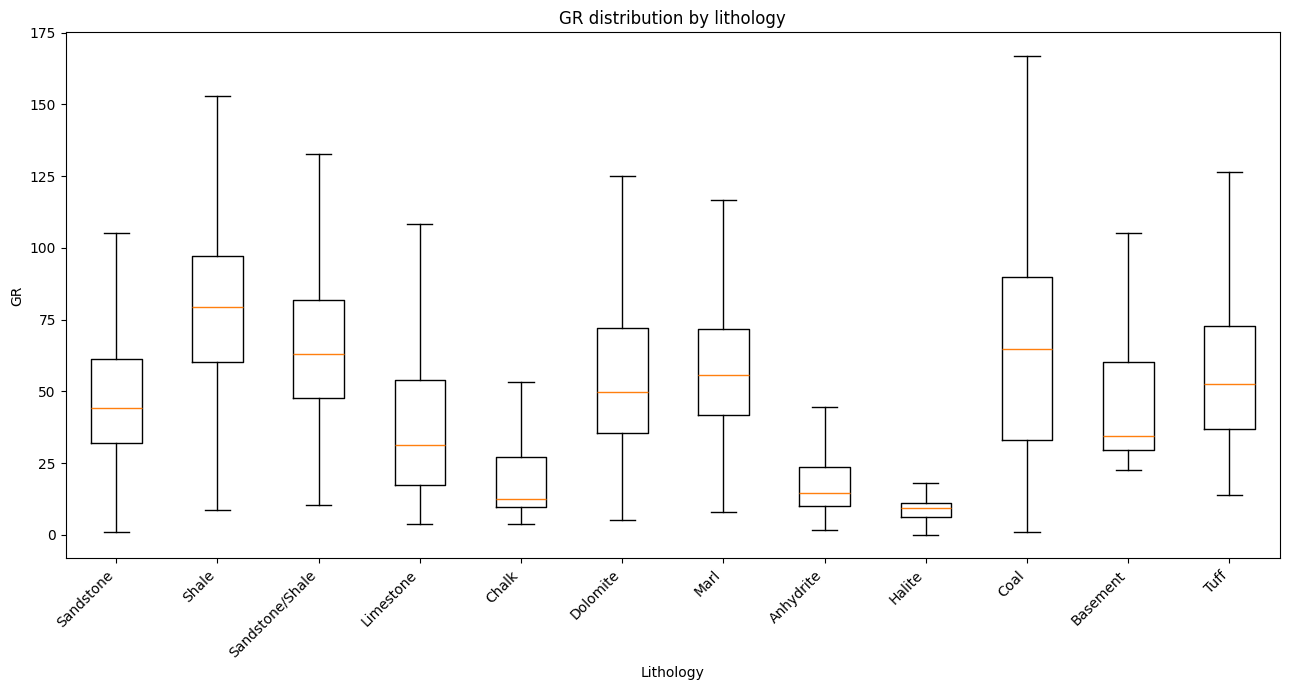

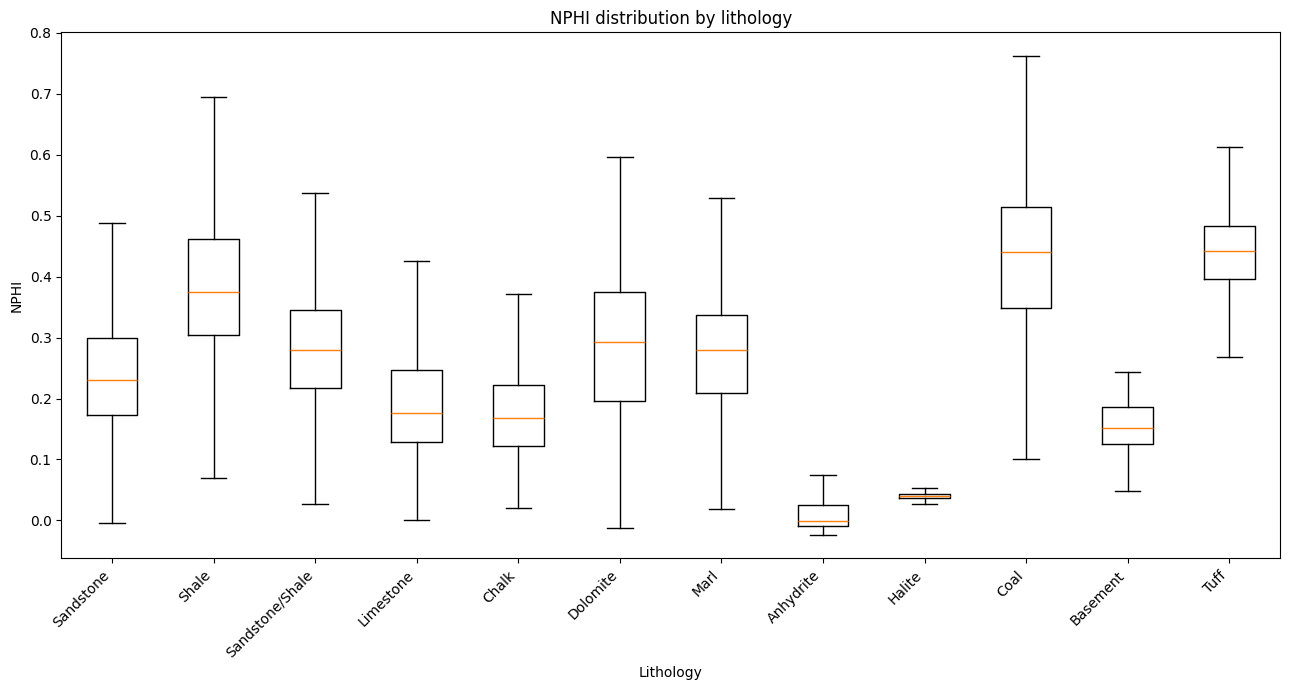

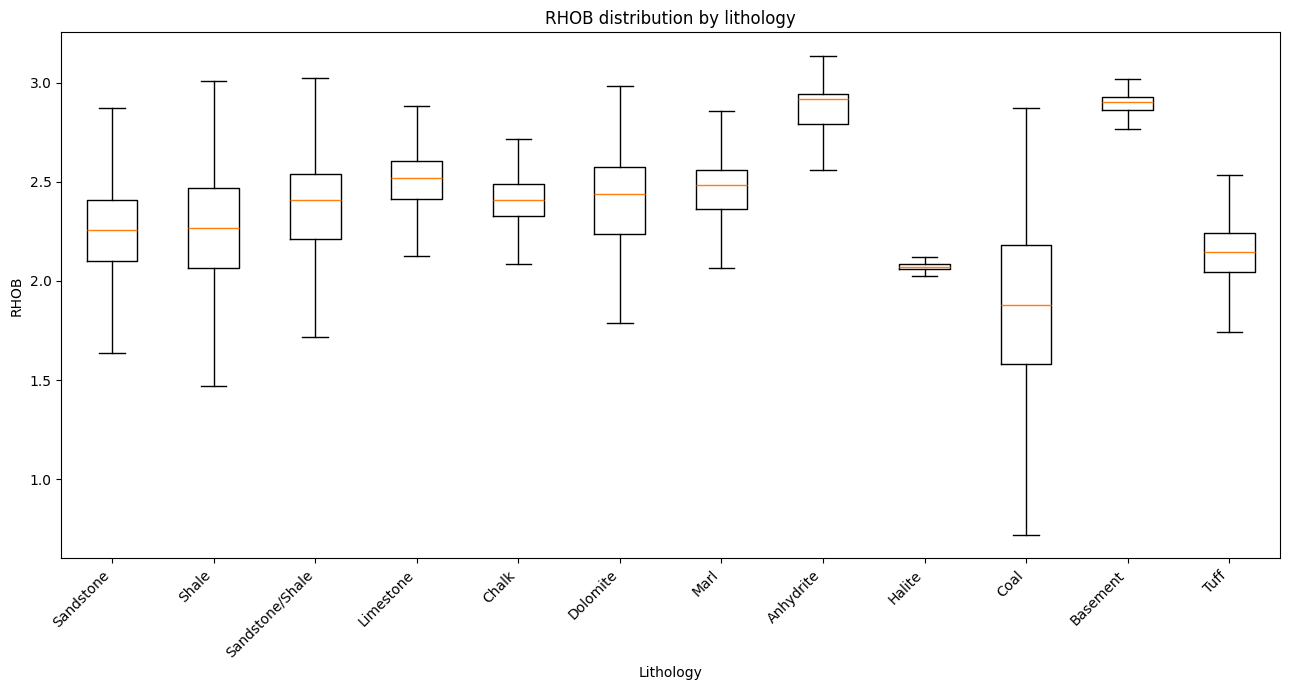

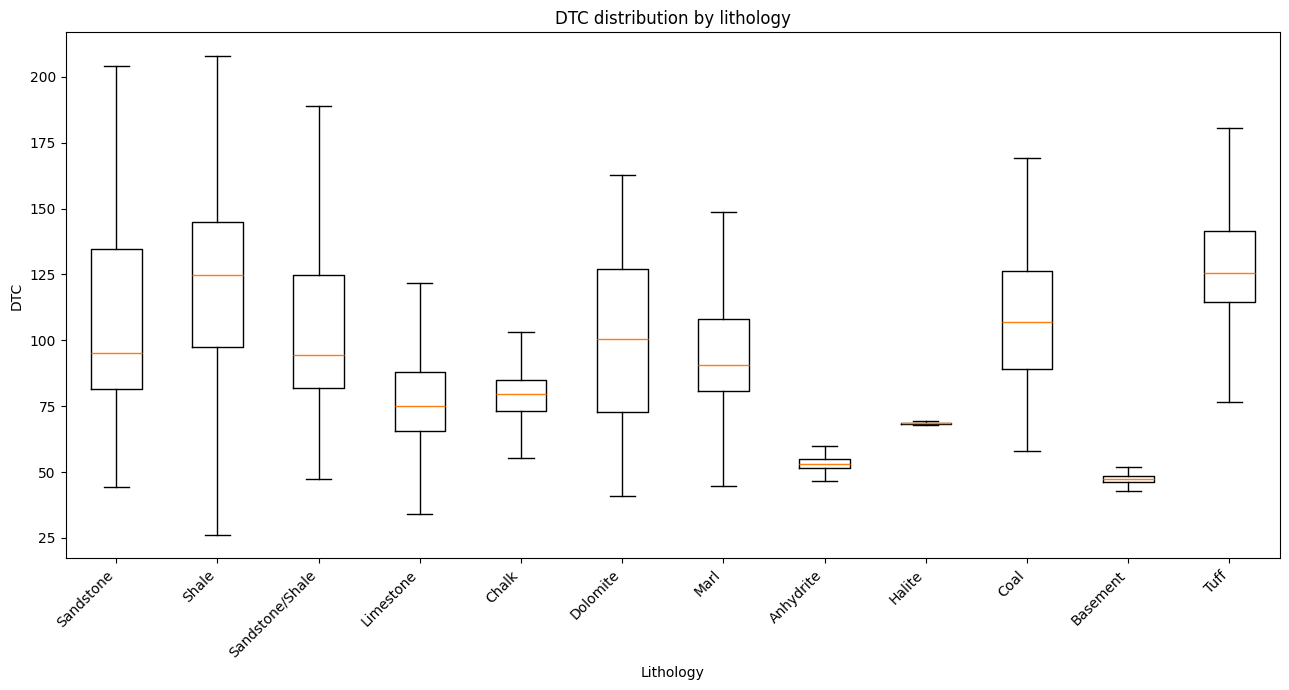

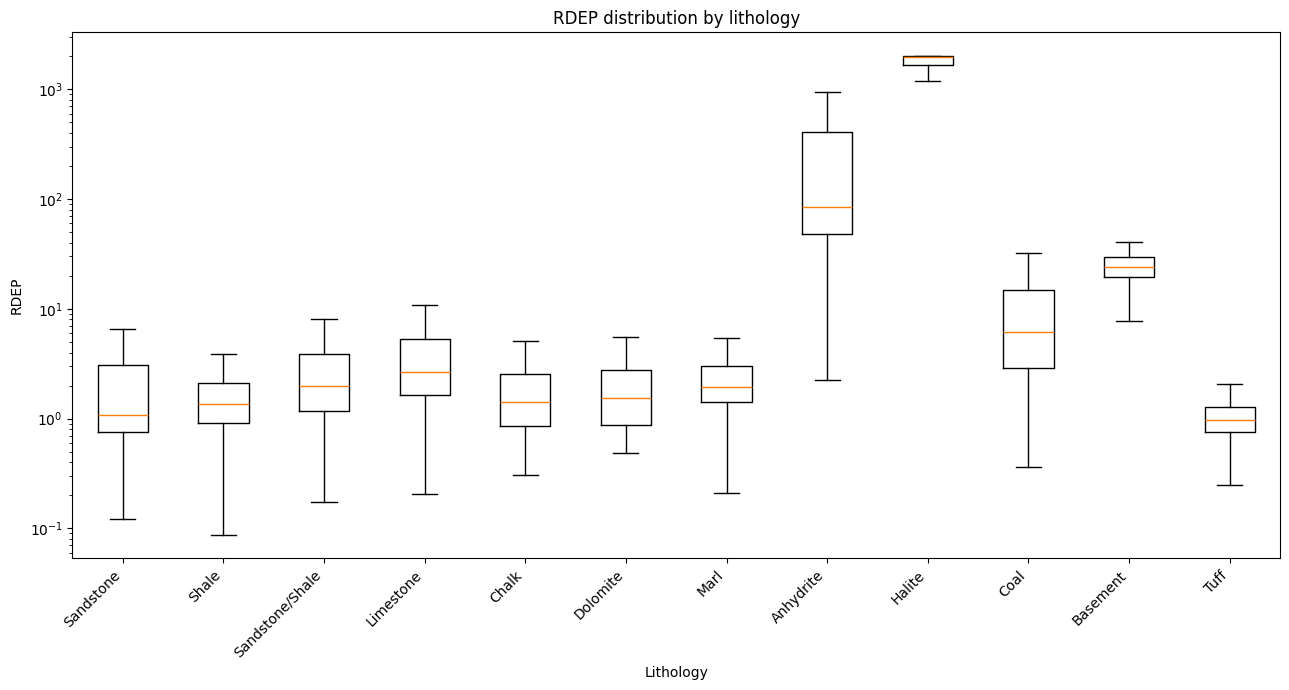

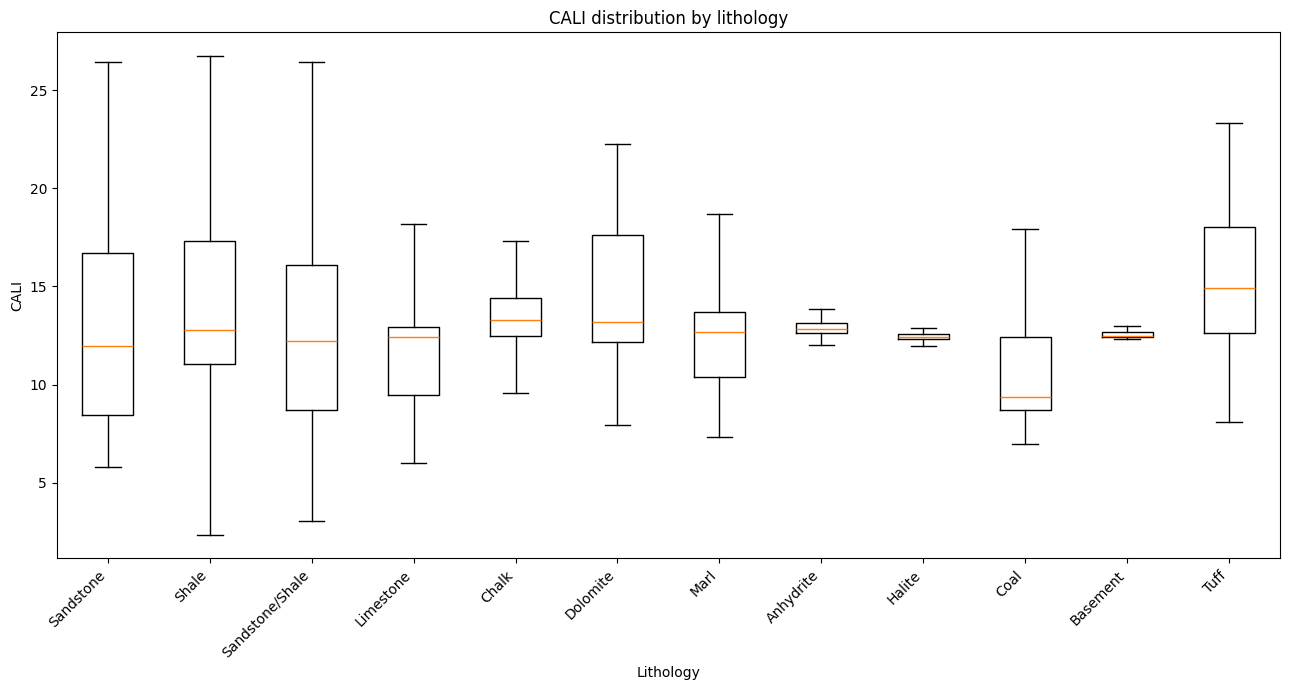

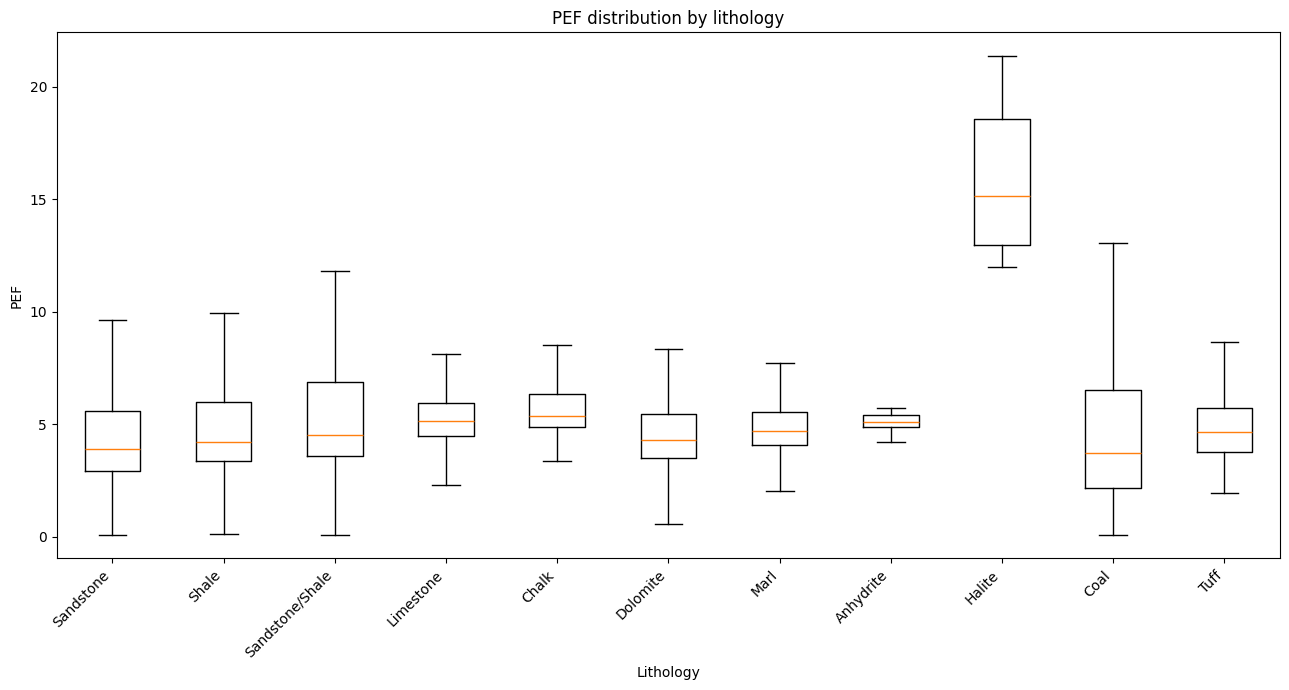

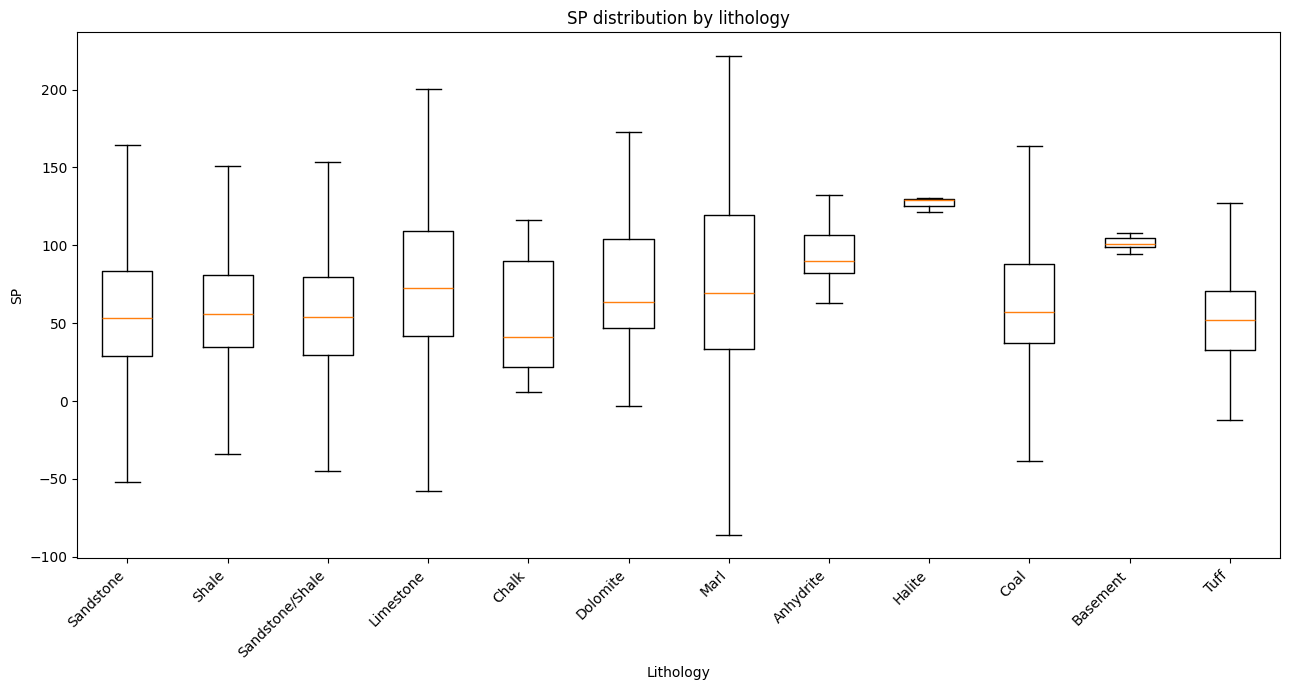

In [22]:
# Boxplots by Lithology, one figure per feature
lithology_order = [
    LITHOLOGY_NAMES[
        code
    ]
    for code
    in LITHOLOGY_CODES
]

for feature in PRIMARY_RAW_FEATURES:
    plot_groups = []
    plot_labels = []

    for lithology_name in lithology_order:
        class_mask = (
            train_raw[
                "LITHOLOGY_NAME"
            ]
            == lithology_name
        )

        class_values = clean_primary.loc[
            class_mask,
            feature,
        ].dropna()

        if class_values.empty:
            continue

        if len(
            class_values
        ) > 20_000:
            class_values = class_values.sample(
                n=20_000,
                random_state=RANDOM_STATE,
            )

        plot_groups.append(
            class_values.to_numpy(
                dtype=float
            )
        )

        plot_labels.append(
            lithology_name
        )

    plt.figure(
        figsize=(13, 7)
    )

    plt.boxplot(
        plot_groups,
        labels=plot_labels,
        showfliers=False,
    )

    if feature == "RDEP":
        plt.yscale(
            "log"
        )

    plt.ylabel(
        feature
    )

    plt.xlabel(
        "Lithology"
    )

    plt.xticks(
        rotation=45,
        ha="right",
    )

    plt.title(
        f"{feature} distribution by lithology"
    )

    save_current_figure(
        f"08_boxplot_by_lithology_{feature}.png"
    )

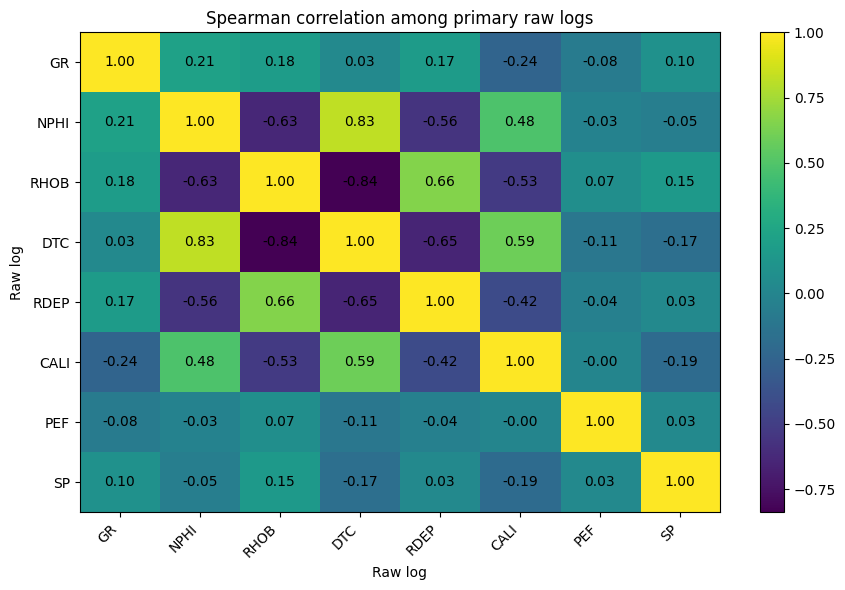

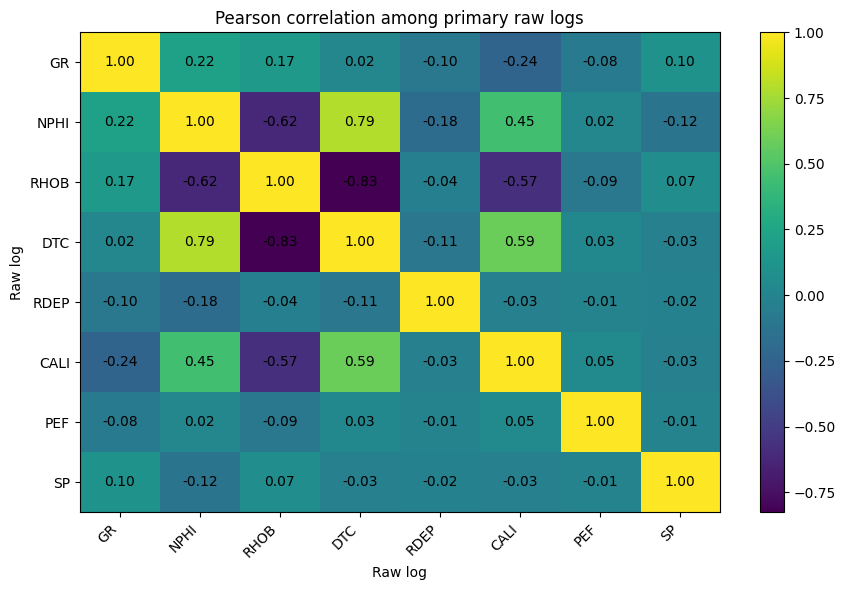

In [23]:
# Spearman correlation heatmap
draw_labeled_heatmap(
    spearman_correlation,
    title=(
        "Spearman correlation among primary raw logs"
    ),
    xlabel="Raw log",
    ylabel="Raw log",
    filename=(
        "09_primary_raw_spearman_correlation.png"
    ),
    annotate=True,
    number_format=".2f",
)


# Pearson correlation heatmap
draw_labeled_heatmap(
    pearson_correlation,
    title=(
        "Pearson correlation among primary raw logs"
    ),
    xlabel="Raw log",
    ylabel="Raw log",
    filename=(
        "10_primary_raw_pearson_correlation.png"
    ),
    annotate=True,
    number_format=".2f",
)

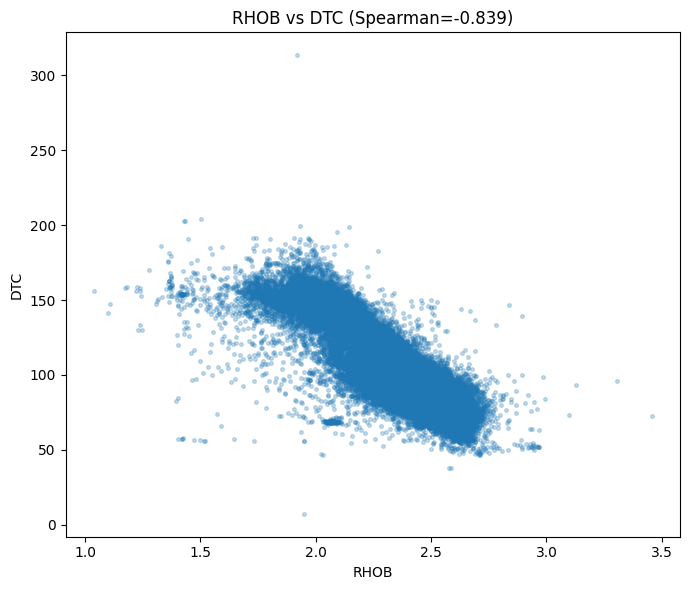

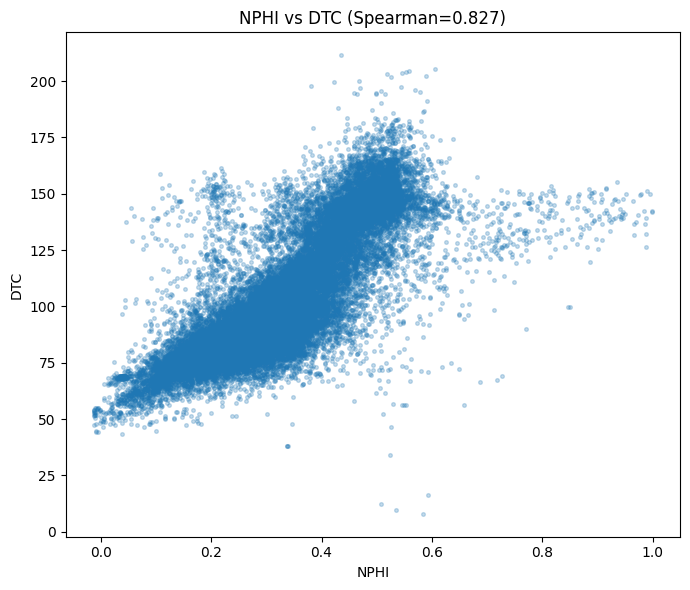

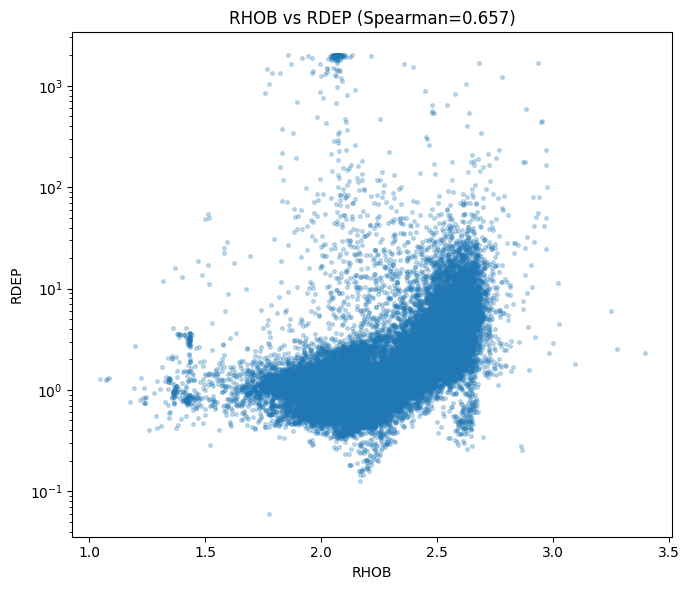

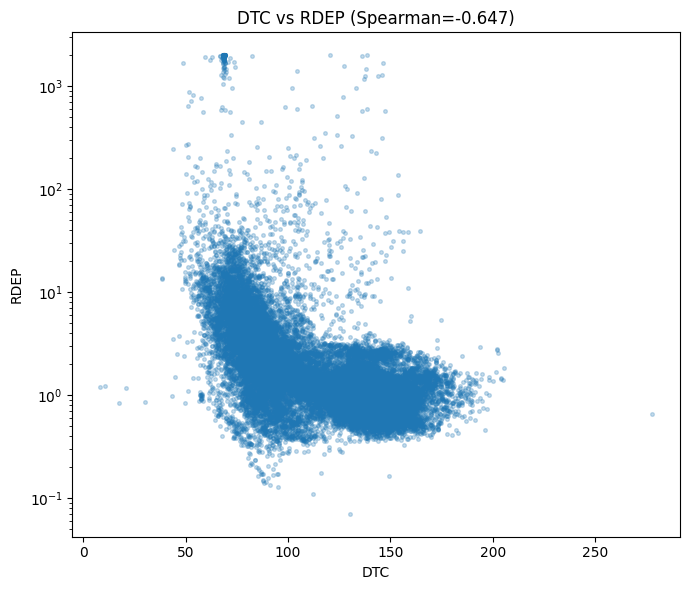

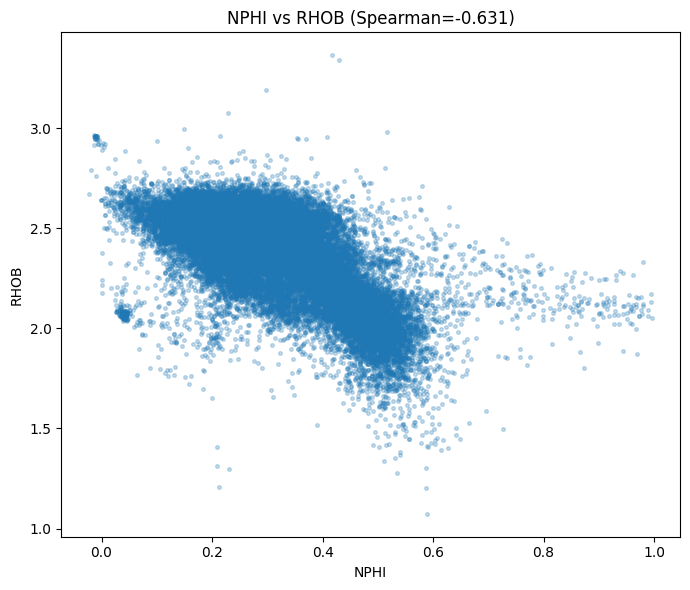

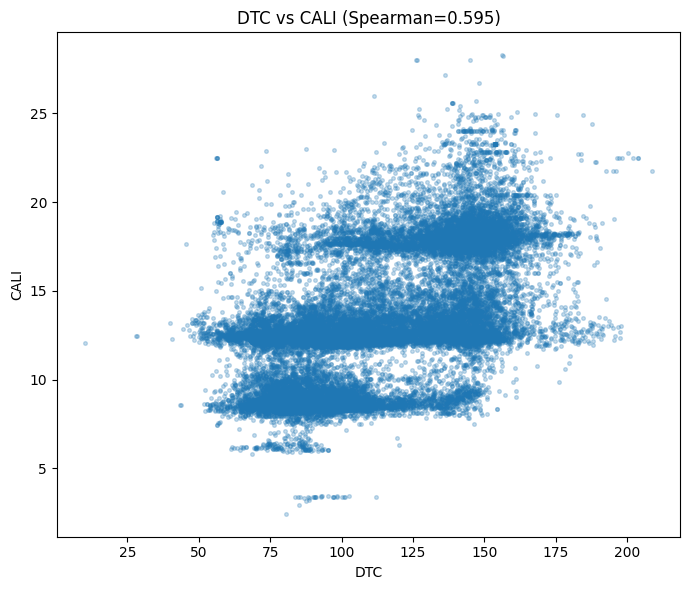

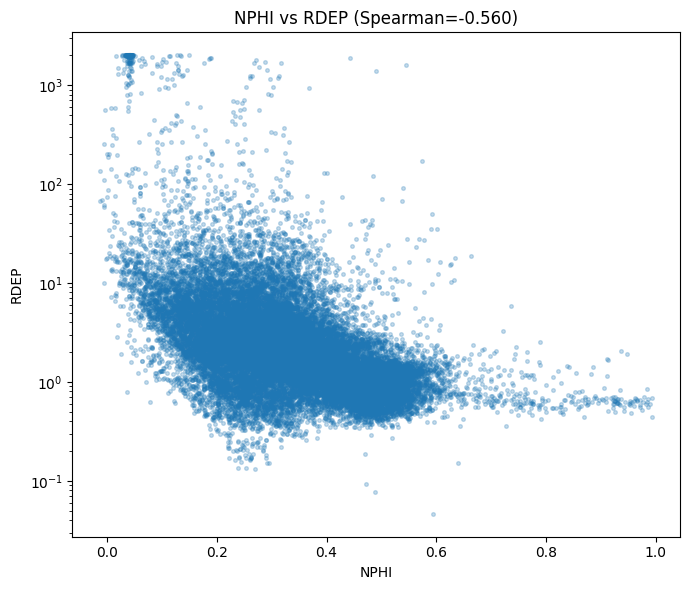

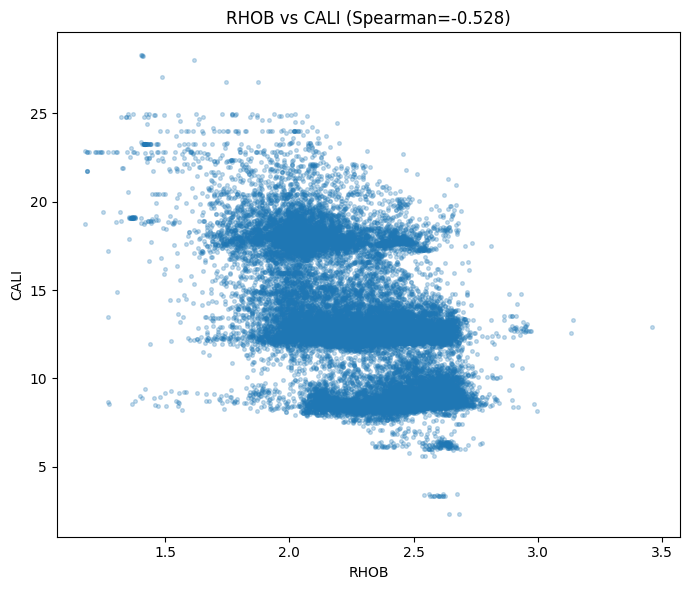

In [24]:
# Scatter plots for the most redundant pairs
top_pairs = pairwise_redundancy.head(
    TOP_REDUNDANT_PAIRS_TO_PLOT
)

for rank, pair_row in top_pairs.iterrows():
    feature_a = pair_row[
        "feature_a"
    ]

    feature_b = pair_row[
        "feature_b"
    ]

    pair_values = clean_primary[
        [
            feature_a,
            feature_b,
        ]
    ].dropna()

    if len(
        pair_values
    ) > MAX_SCATTER_ROWS:
        pair_values = pair_values.sample(
            n=MAX_SCATTER_ROWS,
            random_state=RANDOM_STATE,
        )

    plt.figure(
        figsize=(7, 6)
    )

    plt.scatter(
        pair_values[
            feature_a
        ],
        pair_values[
            feature_b
        ],
        s=7,
        alpha=0.25,
    )

    if feature_a == "RDEP":
        plt.xscale(
            "log"
        )

    if feature_b == "RDEP":
        plt.yscale(
            "log"
        )

    plt.xlabel(
        feature_a
    )

    plt.ylabel(
        feature_b
    )

    plt.title(
        (
            f"{feature_a} vs {feature_b} "
            f"(Spearman={pair_row['spearman_correlation']:.3f})"
        )
    )

    save_current_figure(
        (
            f"11_redundancy_scatter_"
            f"{rank + 1:02d}_{feature_a}_{feature_b}.png"
        )
    )

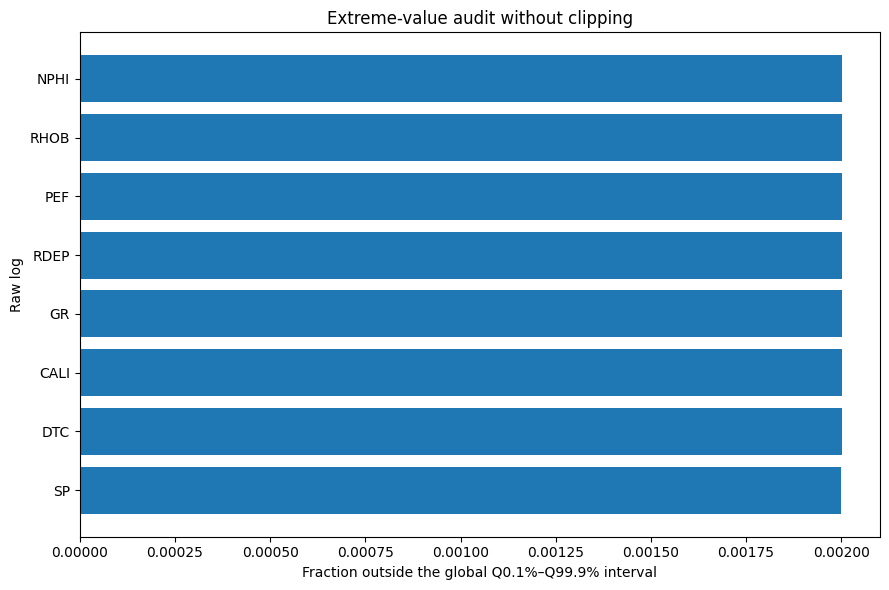

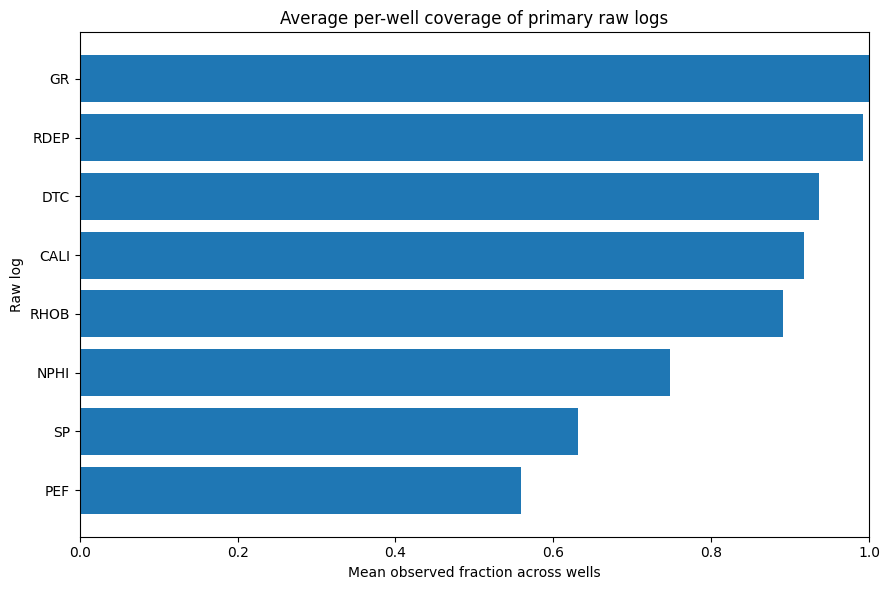

In [25]:
# Extreme-value rate
plot_df = (
    physical_validity_audit.sort_values(
        "outside_q001_q999_rate",
        ascending=True,
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    plot_df[
        "feature"
    ],
    plot_df[
        "outside_q001_q999_rate"
    ],
)

plt.xlabel(
    "Fraction outside the global Q0.1%–Q99.9% interval"
)

plt.ylabel(
    "Raw log"
)

plt.title(
    "Extreme-value audit without clipping"
)

save_current_figure(
    "12_extreme_value_rate.png"
)


# Mean well-level observed rate
well_observed_summary = (
    well_feature_missingness.groupby(
        "feature",
        as_index=False,
    )
    .agg(
        mean_well_observed_rate=(
            "observed_rate",
            "mean",
        ),
        minimum_well_observed_rate=(
            "observed_rate",
            "min",
        ),
        maximum_well_observed_rate=(
            "observed_rate",
            "max",
        ),
    )
    .sort_values(
        "mean_well_observed_rate",
        ascending=True,
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    well_observed_summary[
        "feature"
    ],
    well_observed_summary[
        "mean_well_observed_rate"
    ],
)

plt.xlabel(
    "Mean observed fraction across wells"
)

plt.ylabel(
    "Raw log"
)

plt.xlim(
    0,
    1,
)

plt.title(
    "Average per-well coverage of primary raw logs"
)

save_current_figure(
    "13_mean_well_feature_coverage.png"
)

# 15. Contract gate

In [26]:
primary_audit = (
    overall_raw_feature_audit.loc[
        overall_raw_feature_audit[
            "feature"
        ].isin(
            PRIMARY_RAW_FEATURES
        )
    ]
    .set_index(
        "feature"
    )
)

primary_features_all_present = bool(
    set(
        PRIMARY_RAW_FEATURES
    )
    .issubset(
        set(
            train_raw.columns
        )
    )
)

primary_feature_order_exact = bool(
    list(
        PRIMARY_CONTRACT[
            "input_features"
        ]
    )
    == PRIMARY_RAW_FEATURES
)

no_forbidden_inputs = bool(
    len(
        set(
            PRIMARY_RAW_FEATURES
        )
        & FORBIDDEN_PRIMARY_COLUMNS
    )
    == 0
)

no_engineered_features = bool(
    all(
        infer_column_role(
            feature
        )
        == "primary_raw_measurement"
        for feature
        in PRIMARY_RAW_FEATURES
    )
)

all_primary_features_observed = bool(
    (
        primary_audit[
            "observed_rows"
        ]
        > 0
    ).all()
)

all_primary_features_in_all_folds = bool(
    (
        primary_audit[
            "supporting_folds"
        ]
        == 5
    ).all()
)

all_primary_features_in_enough_wells = bool(
    (
        primary_audit[
            "supporting_wells"
        ]
        >= 20
    ).all()
)

all_primary_features_nonconstant = bool(
    (
        primary_audit[
            "unique_values"
        ]
        >= 10
    ).all()
    and (
        primary_audit[
            "iqr"
        ]
        > EPSILON
    ).all()
)

rdep_nonpositive_removed = bool(
    (
        clean_primary[
            "RDEP"
        ]
        .dropna()
        > 0
    ).all()
)

sp_sentinel_removed = bool(
    not np.isclose(
        clean_primary[
            "SP"
        ]
        .dropna()
        .to_numpy(
            dtype=float
        ),
        -999.0,
        rtol=0.0,
        atol=1e-12,
    ).any()
)

all_folds_present = bool(
    sorted(
        train_raw[
            "GROUP_FOLD"
        ]
        .unique()
        .tolist()
    )
    == [
        1,
        2,
        3,
        4,
        5,
    ]
)

CONTRACT_GATE = {
    "official_test_unused": True,
    "stage_04c_full_transport_bank_passed": bool(
        stage_04c_gate[
            "overall_transport_bank_passed"
        ]
    ),
    "all_five_grouped_folds_present": (
        all_folds_present
    ),
    "primary_features_all_present": (
        primary_features_all_present
    ),
    "primary_feature_order_exact": (
        primary_feature_order_exact
    ),
    "no_forbidden_inputs_in_primary_contract": (
        no_forbidden_inputs
    ),
    "no_engineered_features_in_primary_contract": (
        no_engineered_features
    ),
    "all_primary_features_have_observed_values": (
        all_primary_features_observed
    ),
    "all_primary_features_present_in_all_folds": (
        all_primary_features_in_all_folds
    ),
    "all_primary_features_supported_by_at_least_20_wells": (
        all_primary_features_in_enough_wells
    ),
    "all_primary_features_nonconstant": (
        all_primary_features_nonconstant
    ),
    "SP_minus_999_removed": (
        sp_sentinel_removed
    ),
    "RDEP_nonpositive_values_removed": (
        rdep_nonpositive_removed
    ),
    "fold_safe_median_imputation_policy_locked": True,
    "missingness_indicators_disabled": True,
    "scaling_disabled": True,
    "feature_engineering_disabled": True,
    "outlier_clipping_disabled": True,
}

CONTRACT_GATE[
    "overall_raw_feature_contract_passed"
] = bool(
    all(
        CONTRACT_GATE.values()
    )
)

print(
    json.dumps(
        CONTRACT_GATE,
        indent=2,
    )
)

if not CONTRACT_GATE[
    "overall_raw_feature_contract_passed"
]:
    raise RuntimeError(
        "Raw-log feature contract gate failed."
    )

print(
    "\n✅ Raw-log feature contract passed."
)

{
  "official_test_unused": true,
  "stage_04c_full_transport_bank_passed": true,
  "all_five_grouped_folds_present": true,
  "primary_features_all_present": true,
  "primary_feature_order_exact": true,
  "no_forbidden_inputs_in_primary_contract": true,
  "no_engineered_features_in_primary_contract": true,
  "all_primary_features_have_observed_values": true,
  "all_primary_features_present_in_all_folds": true,
  "all_primary_features_supported_by_at_least_20_wells": true,
  "all_primary_features_nonconstant": true,
  "SP_minus_999_removed": true,
  "RDEP_nonpositive_values_removed": true,
  "fold_safe_median_imputation_policy_locked": true,
  "missingness_indicators_disabled": true,
  "scaling_disabled": true,
  "feature_engineering_disabled": true,
  "outlier_clipping_disabled": true,
  "overall_raw_feature_contract_passed": true
}

✅ Raw-log feature contract passed.


In [27]:
column_role_inventory.to_csv(
    OUTPUT_DIR
    / "00_column_role_inventory.csv",
    index=False,
)

overall_raw_feature_audit.to_csv(
    OUTPUT_DIR
    / "01_overall_raw_feature_audit.csv",
    index=False,
)

fold_feature_coverage.to_csv(
    OUTPUT_DIR
    / "02_fold_feature_coverage.csv",
    index=False,
)

class_feature_missingness.to_csv(
    OUTPUT_DIR
    / "03_class_feature_missingness.csv",
    index=False,
)

well_feature_missingness.to_csv(
    OUTPUT_DIR
    / "04_well_feature_missingness.csv",
    index=False,
)

well_complete_feature_count.to_csv(
    OUTPUT_DIR
    / "05_well_raw_feature_coverage_summary.csv",
    index=False,
)

physical_validity_audit.to_csv(
    OUTPUT_DIR
    / "06_physical_validity_and_extreme_value_audit.csv",
    index=False,
)

spearman_correlation.to_csv(
    OUTPUT_DIR
    / "07_spearman_correlation_matrix.csv",
)

pearson_correlation.to_csv(
    OUTPUT_DIR
    / "08_pearson_correlation_matrix.csv",
)

pairwise_redundancy.to_csv(
    OUTPUT_DIR
    / "09_pairwise_redundancy_summary.csv",
    index=False,
)

with open(
    OUTPUT_DIR
    / "10_primary_raw_feature_contract.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        PRIMARY_CONTRACT,
        file,
        ensure_ascii=False,
        indent=2,
    )

with open(
    OUTPUT_DIR
    / "11_extended_raw_candidate_contract.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        EXTENDED_CANDIDATE_CONTRACT,
        file,
        ensure_ascii=False,
        indent=2,
    )

with open(
    OUTPUT_DIR
    / "12_fold_safe_preprocessing_policy.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        PREPROCESSING_POLICY,
        file,
        ensure_ascii=False,
        indent=2,
    )

with open(
    OUTPUT_DIR
    / "13_raw_feature_contract_gate.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        CONTRACT_GATE,
        file,
        ensure_ascii=False,
        indent=2,
    )

run_configuration = {
    "stage": (
        "05A_raw_log_feature_contract"
    ),
    "run_mode": RUN_MODE,
    "official_test_used": False,
    "train_path": str(
        TRAIN_PATH
    ),
    "fold_assignment_path": str(
        FOLD_ASSIGNMENT_PATH
    ),
    "primary_features": (
        PRIMARY_RAW_FEATURES
    ),
    "extended_present_features": (
        present_extended_features
    ),
    "extended_eligible_features": (
        extended_eligible_features
    ),
    "forbidden_primary_columns": sorted(
        FORBIDDEN_PRIMARY_COLUMNS
    ),
    "preprocessing": (
        PREPROCESSING_POLICY
    ),
    "next_stage": (
        "05B_raw_log_RF_grouped_well_CV"
    ),
    "claim_scope": (
        "diagnostic raw-log representation and fold-safe input contract"
    ),
}

with open(
    OUTPUT_DIR
    / "14_run_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

file_hashes = {
    "train_csv_sha256": sha256_file(
        TRAIN_PATH
    ),
    "fold_assignment_sha256": sha256_file(
        FOLD_ASSIGNMENT_PATH
    ),
}

with open(
    OUTPUT_DIR
    / "15_input_file_hashes.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        file_hashes,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Outputs saved in:")
print(OUTPUT_DIR)

print("\nPlots saved in:")
print(PLOT_DIR)

Outputs saved in:
${STRATASHIFT_ARTIFACT_ROOT}/05A_raw_log_feature_contract/full

Plots saved in:
${STRATASHIFT_ARTIFACT_ROOT}/05A_raw_log_feature_contract/full/plots
